In [2]:
import cartopy.crs as ccrs
from cmap import Colormap
from enum import IntEnum
from functools import partial
import geopandas as gpd
from itertools import product
from jllutils import miscutils
import jllutils.plots as jplt
from loguru import logger
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.gridspec import GridSpec
from matplotlib.patches import ConnectionPatch
import matplotlib.pyplot as plt
from netCDF4 import Dataset
import numpy as np
import pandas as pd
from pathlib import Path
import rasterio
import re
import seaborn as sns
from shapely import Geometry, Polygon
from scipy.stats import percentileofscore, spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import RobustScaler
import statsmodels.api as sm
import sys
import tomllib

import pynbcode.aerosols as nbaer
import pynbcode.carb as nbcarb
import pynbcode.constants as nbcst
import pynbcode.enhancement_ratios as nber
import pynbcode.er_frp_analysis as nberf
import pynbcode.gridded_data as nbgrid
import pynbcode.plots as nbplt
import pynbcode.plot_utils as nbpu
import pynbcode.tropomi.custom_ret_checks as nbtrcrc
import pynbcode.structures as nbstruct
import pynbcode.utils as nbutils

import pynbcode.tropess.tropess_data as nbtrdat

# Quantifying Reactive Nitrogen Emissions from Wildland-Urban Interface Fires: A Case Study of the 2025 Los Angeles Fires

In [3]:
sys.path.append('static-data/tropomi-custom/')

In [4]:
import make_custom_l2

pyephem not installed, solar noon functions will not work


In [5]:
logger.remove()
logger.add(sys.stderr, level='INFO')

1

## Load common data

In [5]:
with open('static-data/download-config-small.toml', 'rb') as f:
    LA_CFG = tomllib.load(f)

with open('static-data/download-config-anderson.toml', 'rb') as f:
    ANDERSON_CFG = tomllib.load(f)

In [6]:
STRUCTURE_DAMAGE_GDF = nbstruct.load_structures_damage_df()

In [6]:
CALFIRE_DF = pd.read_csv('static-data/fire-progression/California_Historic_Fire_Perimeters.csv')

In [7]:
GOES_FRP_LA_ONLY = nberf.GoesFrpProvider('static-data/goes/eaton_and_palisades-la_basin-goes_summary.nc')
GOES_WEST_COAST_FRP = nberf.GoesMultiSceneFrpProvider('static-data/goes/')
MODIS_TERRA_FRP = nberf.ModisFrpProvider('static-data/modis/terra/')
VIIRS_JPSS2_FRP = nberf.ViirsFrpProvider('static-data/viirs/jpss-2/fire_nrt_J2V-C2_all_jan.json')
VIIRS_WEST_COAST_FRP = nberf.ViirsMultiJsonFrpProvider(
    'static-data/viirs/jpss-1/fire_archive_J1V-2020_west_coast.json',
    'static-data/viirs/jpss-1/fire_archive_J1V-2021_west_coast.json',
)
PERIMETERS_GDF = gpd.read_file('static-data/fire-progression/fire-perimeters.geojson')

static-data/modis/terra/MOD14.A2025007.0535.061.2025007083453.hdf has no fires
static-data/modis/terra/MOD14.A2025007.0540.061.2025007083540.hdf has no fires
static-data/modis/terra/MOD14.A2025010.0600.061.2025010150018.hdf has no fires


In [8]:
SLOPE_ER_PROVIDER = nberf.SlopeErMultiSceneProvider(
    ANDERSON_CFG['scene'],
    enhancement_dir='static-data/tropomi/enhancements/'
)

LA_SLOPE_ER = nberf.SlopeErMultiSceneProvider(
    LA_CFG['scene'],
    'static-data/tropomi/enhancements/'
)

LA_SLOPE_ER_CUST_NO2_R1 = nberf.SlopeErMultiSceneProvider(
    LA_CFG['scene'],
    'static-data/tropomi-custom/tropess-dco-ratio/ratio-0.01000/enhancements/'
)

LA_SLOPE_ER_CUST_NO2_R2 = nberf.SlopeErMultiSceneProvider(
    LA_CFG['scene'],
    'static-data/tropomi-custom/tropess-dco-ratio/ratio-0.02000/enhancements/'
)

In [9]:
CUSTOM_ENH_DIRS_GAUSSIAN = tuple(Path('static-data/tropomi-custom/gaussian/').glob('*/enhancements'))
CUSTOM_ENH_DIRS_TROPESS = tuple(Path('static-data/tropomi-custom/tropess-dco-ratio/').glob('*/enhancements'))
CUSTOM_ENH_DIRS_WRFCHEM = tuple(Path('static-data/tropomi-custom/wrf-chem/').glob('enhancements'))
ALL_LA_ONLY_CUSTOM_ENH_DIRS = CUSTOM_ENH_DIRS_TROPESS + CUSTOM_ENH_DIRS_WRFCHEM
ALL_CUSTOM_GAUSSIAN_ENH_DIRS = (
    CUSTOM_ENH_DIRS_GAUSSIAN +
    tuple(Path('static-data/tropomi-custom/gaussian-aerosol/').glob('*/enhancements'))
)

In [10]:
LA_PLUME_MASK = nbplt.PlumeMask.from_enhancement('static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc')
LA_CUSTOM_PLUME_MASK = nbplt.PlumeMask.from_enhancement('static-data/tropomi-custom/tropess-dco-ratio/ratio-0.01000/enhancements/enhancement_eaton_and_palisades.nc')

In [11]:
CARB_NOX = nbcarb.load_carb_no_no2('static-data/carb/')
SCAB_NO2_VS_CO = pd.read_csv('static-data/scaqmd/NO2_CO_SCAB_2025.csv')

## Structures affected

In [12]:
def print_n_damaged_and_destroyed(structures_df, incident_names):
    tot_dmg = 0
    tot_destroyed = 0
    for name in incident_names:
        dmg_df = nbstruct.subset_structures(structures_df, name, min_damage=nbstruct.DamageLevel.AFFECTED, max_damage=nbstruct.DamageLevel.MAJOR)
        destroyed_df = nbstruct.subset_structures(structures_df, name, min_damage=nbstruct.DamageLevel.DESTROYED)

        tot_dmg += dmg_df.shape[0]
        tot_destroyed += destroyed_df.shape[0]
        
        print(f'{name}: {dmg_df.shape[0]} damaged, {destroyed_df.shape[0]} destroyed')

    print(f'Total: {tot_dmg} damaged, {tot_destroyed} destroyed')

In [13]:
print_n_damaged_and_destroyed(STRUCTURE_DAMAGE_GDF, ['Palisades', 'Eaton'])

Palisades: 975 damaged, 6845 destroyed
Eaton: 1076 damaged, 9419 destroyed
Total: 2051 damaged, 16264 destroyed


## Standard retrieval plumes

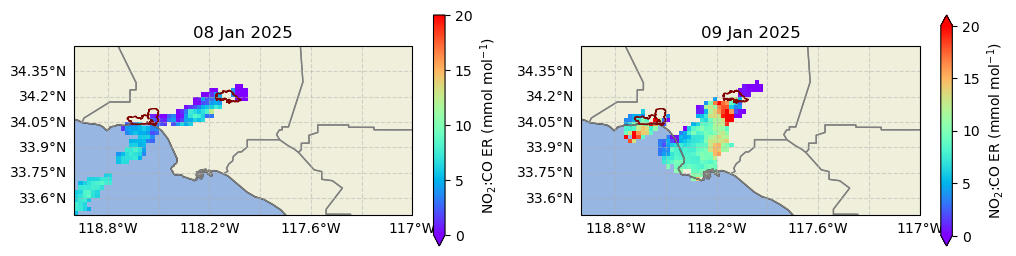

In [79]:
dates = pd.date_range('2025-01-08', '2025-01-09')

n = dates.size
_, axs = plt.subplots(1, n, figsize=(6*n, 3), subplot_kw={'projection': ccrs.PlateCarree()})

for ax, date in zip(axs, dates):
    nbplt.plot_gridded_enhancement(
        'static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc',
        date=date,
        variable='Time/enhancement_ratio',
        extent=nbcst.LA_EXTENT,
        vmin=0, vmax=20, cmap='rainbow',
        plume_mask=LA_PLUME_MASK,
        cblabel='NO$_2$:CO ER ({units})',
        show_mean_er=False,
        feature_kws={'land': True, 'ocean': True}, ax=ax
    )
    ax.set_title(date.strftime('%d %b %Y'))
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'palisades', edgecolor='maroon', facecolor='none'
    )
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'eaton', edgecolor='maroon', facecolor='none'
    )
plt.savefig('figures/tropomi-std-ers.pdf', bbox_inches='tight')

Use just Jan 9th for the graphical abstract.

In [111]:
nbcst.LA_EXTENT

[-119.0, -117.0, 33.5, 34.5]

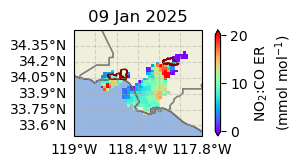

In [112]:
_, ax = plt.subplots(figsize=(9/2.54, 3.5/2.54), subplot_kw={'projection': ccrs.PlateCarree()})

date = pd.Timestamp(2025,1,9)
nbplt.plot_gridded_enhancement(
    'static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc',
    date=date,
    variable='Time/enhancement_ratio',
    extent=[-119.0, -117.8, 33.5, 34.5],
    vmin=0, vmax=20, cmap='rainbow',
    plume_mask=LA_PLUME_MASK,
    cblabel='NO$_2$:CO ER\n({units})',
    show_mean_er=False,
    feature_kws={'land': True, 'ocean': True}, ax=ax
)
ax.set_title(date.strftime('%d %b %Y'))
nbpu.add_fire_perimeter(
    ax, 'static-data/fire-progression/fire-perimeters.geojson',
    'palisades', edgecolor='maroon', facecolor='none'
)
nbpu.add_fire_perimeter(
    ax, 'static-data/fire-progression/fire-perimeters.geojson',
    'eaton', edgecolor='maroon', facecolor='none'
)
plt.savefig('figures/tropomi-std-ers-jan09.pdf', bbox_inches='tight')

## Custom retrieval plumes

In [15]:
def plot_mean_ers_for_dates(enh_file, dates, x_offset=pd.Timedelta(0), plume_mask=None, extent=None, ax=None, er_axis='y', **plot_kws):
    mean_ers = np.full(dates.size, np.nan)
    sigma_ers = np.full(dates.size, np.nan)
    for idate, date in enumerate(dates):
        er_dict = nber.load_enhancements_for_date(
            grid_file=enh_file, date=date, variable='Time/enhancement_ratio',
            plume_mask=plume_mask, extent=extent
        )
        ers = er_dict['values']
        mean_ers[idate] = np.nanmean(ers)
        sigma_ers[idate] = np.nanstd(ers, ddof=1)

    ax = ax or plt.gca()
    plot_kws.setdefault('ls', 'none')
    plot_kws.setdefault('marker', 'o')

    if er_axis == 'y':
        date_axis = ax.xaxis
        set_er_label = ax.set_ylabel
        ax.errorbar(dates + x_offset, mean_ers, yerr=sigma_ers, **plot_kws)
    elif er_axis == 'x':
        date_axis = ax.yaxis
        set_er_label = ax.set_xlabel
        ax.errorbar(mean_ers, dates + x_offset, xerr=sigma_ers, **plot_kws)
    else:
        raise ValueError('er_axis must be "x" or "y"')
        
    
    set_er_label('NO$_2$:CO mean enhancement ratio (mmol mol$^{-1}$)')
    plt.setp(date_axis.get_majorticklabels(), rotation=90)
    date_axis.set_major_locator(mdates.DayLocator(interval=1))
    date_axis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.grid(True, axis=er_axis)

In [124]:
def plot_scab_no2_vs_co(scab_df=SCAB_NO2_VS_CO):
    _, axs = plt.subplots(1, 3, figsize=(12,4), gridspec_kw={'wspace': 0.33})

    x = 0.5
    scab_df[scab_df['CO (ppm)'] > x].plot(y='NO2 (ppm)/CO (ppm)', x='CO (ppm)', ls='None', marker='.', label='', ax=axs[0])
    axs[0].set_title(f'CO > {x:.2f} ppm')
    axs[0].get_legend().remove()
    
    
    x = np.quantile(scab_df['CO (ppm)'].dropna(), 0.99)
    scab_df[scab_df['CO (ppm)'] > x].plot(y='NO2 (ppm)/CO (ppm)', x='CO (ppm)', ls='None', marker='.', label='', ax=axs[1])
    m = scab_df[scab_df['CO (ppm)'] > x]['NO2 (ppm)/CO (ppm)'].mean()
    axs[1].axhline(m, label=f'Mean = {m:.3f}', color='k', ls='--')
    axs[1].set_title(f'CO > {x:.2f} ppm (99th %ile)')
    axs[1].legend()
    
    x = np.quantile(scab_df['CO (ppm)'].dropna(), 0.999)
    scab_df[scab_df['CO (ppm)'] > x].plot(y='NO2 (ppm)/CO (ppm)', x='CO (ppm)', ls='None', marker='.', label='', ax=axs[2])
    axs[2].set_title(f'CO > {x:.2f} ppm (99.9th %ile)')
    m = scab_df[scab_df['CO (ppm)'] > x]['NO2 (ppm)/CO (ppm)'].mean()
    axs[2].axhline(m, label=f'Mean = {m:.3f}', color='k', ls='--')
    axs[2].set_title(f'CO > {x:.2f} ppm (99.9th %ile)')
    axs[2].legend()

    for ax in axs:
        ax.set_xlabel('CO (ppm)')
        ax.set_ylabel('NO$_2$ / CO (unitless)')
        ax.grid(True)

def plot_scab_timelines(scab_df=SCAB_NO2_VS_CO):

        
    _, ax = plt.subplots(figsize=(12,4))
    _, _, ax2 = jplt.create_twin_axes_with_color(color1='tab:blue', color2='tab:orange', ax=ax)
    for _, site_df in scab_df.groupby('site'):
        times = pd.to_datetime(site_df['Time (PST)'], format='%m/%d/%Y %I:%M %p')
        tt = (times >= pd.Timestamp(2025,1,7)) & (times <= pd.Timestamp(2025,1,11))
        ax.plot(times[tt], site_df.loc[tt, 'CO (ppm)'], color='tab:blue')
        ax2.plot(times[tt], site_df.loc[tt, 'NO2 (ppm)']*1e3, lw=0.5, color='tab:orange')
    ax2.set_ylabel('NO$_2$ (ppb)')
    ax.set_ylabel('CO (ppm)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%I %p %b %d'))
    ax.grid(axis='x')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=30, ha='right')

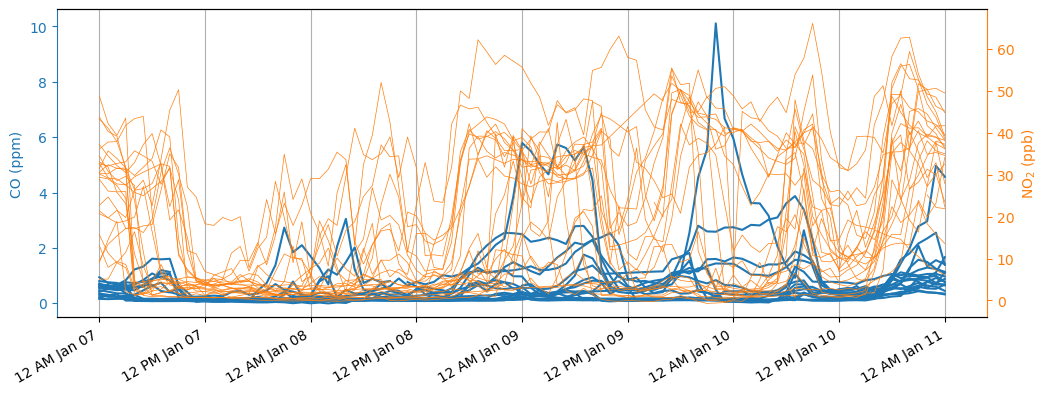

In [17]:
plot_scab_timelines()
plt.savefig('scab_no2_and_co_timeseries.pdf', bbox_inches='tight')

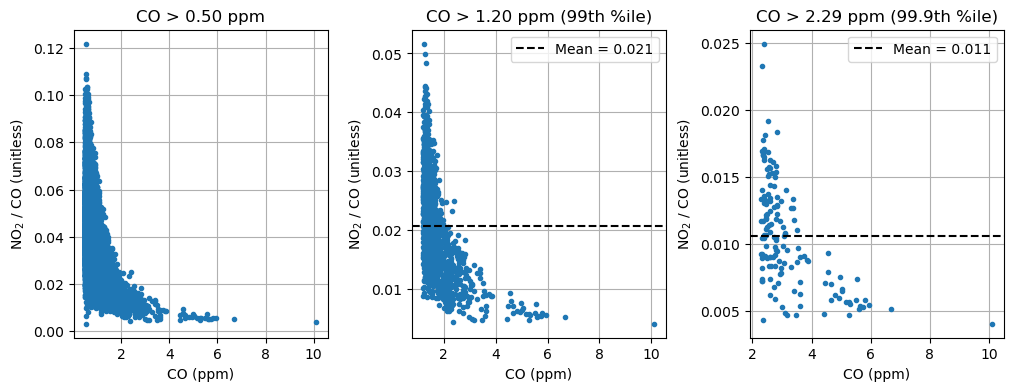

In [125]:
plot_scab_no2_vs_co()
plt.savefig('figures/scab_no2_vs_co.png', bbox_inches='tight')

In [19]:
def custom_priors_example(date=pd.Timestamp(2025,1,8), tgt_lon=-118.5, tgt_lat=34.0, tgt_time=pd.Timestamp(2025,1,8,18,10)):
    _, axs = plt.subplots(1, 2, figsize=(12,4), sharey=True)

    ratio = 0.01
    interp = make_custom_l2.COEnhtoNO2LatLonPresInterp.for_date(
        no2_to_x_ratio=ratio,
        fire_date=date,
        bckgnd_start=pd.Timestamp(2025,1,1),
        bckgnd_end=pd.Timestamp(2025,1,6)
    )
    new_pres = np.linspace(1, 1e5, 10)

    # _, ax, ax2 = jplt.create_twin_axes_with_color(color2='gray', twin='y')
    ax = axs[0]

    ax.plot(
        1e9*interp.tropomi_interp(tgt_lon, tgt_lat, new_pres, tgt_time), new_pres*1e-2,
        marker='^', color='black', label='TROPOMI NO$_2$ prior'
    )
    
    ax.plot(
        1e9*interp.tropess_interp(tgt_lon, tgt_lat, new_pres, tgt_time), new_pres*1e-2,
        marker='o', color='tab:blue', label=f'TROPESS CO $\\cdot$ {ratio} mol NO$_2$/mol CO'
    )

    ax.plot(
        1e9*interp(tgt_lon, tgt_lat, new_pres, tgt_time), new_pres*1e-2,
        marker='x', color='tab:red', label='Combined custom prior'
    )
    
    ax.set_xlabel('NO$_2$ VMR (ppb)')
    ax.set_ylabel('Pressure (hPa)')
    ax.invert_yaxis()
    ax.grid(axis='y')
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.025))

    ax = axs[1]

    first = True
    colors = {25: 'tab:blue', 100: 'tab:orange', 150: 'tab:red'}
    ls = {900: '--', 800: ':', 560: '-.'}
    for (pmid, xmax) in product([900, 800, 560], [25, 100, 150]):
        interp = make_custom_l2.TropomiPriorPlusGaussianLatLonPresInterp.for_date(
            date=date, plume_pmid=pmid*1e2, plume_pwidth=5000, plume_max_dmf=xmax*1e-9
        )
        ax.plot(
            1e9*interp(tgt_lon, tgt_lat, new_pres, tgt_time), new_pres*1e-2,
            color=colors[xmax], ls=ls[pmid], label=f'{pmid} hPa & {xmax} ppb',
        )
        
    ax.grid(axis='y')
    ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.025))

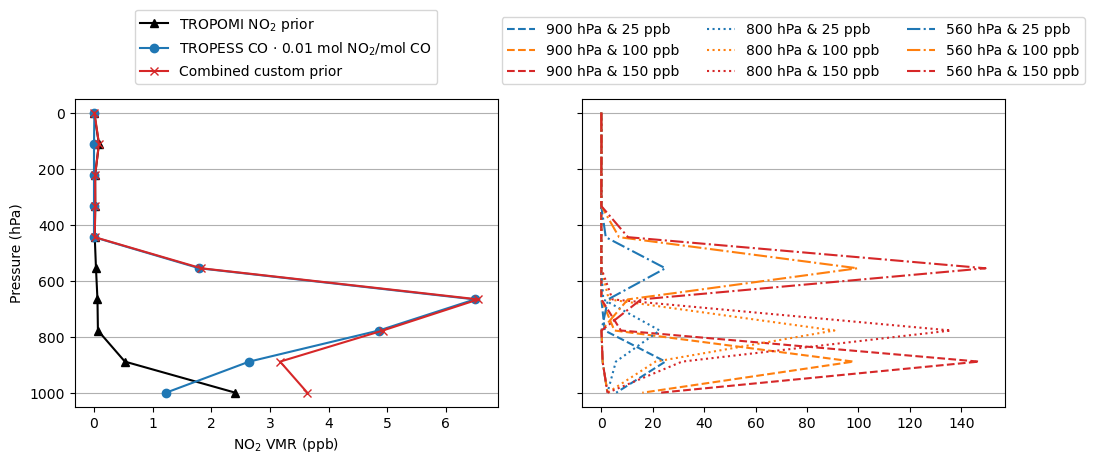

In [20]:
custom_priors_example()
plt.savefig('figures/custom-priors-example.pdf', bbox_inches='tight')

In [21]:
def plot_tropess_profile_ensemble(
    species: str,
    date: pd.Timestamp,
    extents: list[float],
    vscale: float = 1.0,
    units: str = 'mol/mol',
    good_only: bool = False,
    day_only: bool = True,
    cbcolumn: str = 'total',
    cmap='viridis',
    vmin=None,
    vmax=None,
    ax = None
):
    data = nbtrdat.load_tropess_cols(tropess_dir='static-data/tropess-daac/standard/', species=species, date=date)
    ii = nbtrdat.make_filter_index(data, extents=extents, good_only=good_only, day_only=day_only)
    xvals = data['x'][ii]
    xvals[xvals < -990] = np.nan
    xvals *= vscale
    pvals = data['p'][ii]
    pvals[pvals < -990] = np.nan

    icol = nbtrdat.TROPESS_COL_INDS[cbcolumn]
    cvals = data['columns'][ii, icol] * vscale / data['air_columns'][ii, icol]

    if vmin is None:
        vmin = np.nanmin(cvals)
    if vmax is None:
        vmax = np.nanmax(cvals)

    cmapper = jplt.ColorMapper(vmin, vmax, cmap=cmap)
    ax = ax or plt.gca()
    for x, p, c in zip(xvals, pvals, cvals):
        ax.plot(x, p, color=cmapper(c), lw=0.5)
    plt.colorbar(cmapper, ax=ax, label=f'{species.upper()} {cbcolumn} column avg. ({units})')
    if not ax.yaxis_inverted():
        ax.invert_yaxis()
    ax.grid(True)
    ax.set_ylabel('Pressure (hPa)')
    ax.set_xlabel(f'{species.upper()} ({units})')

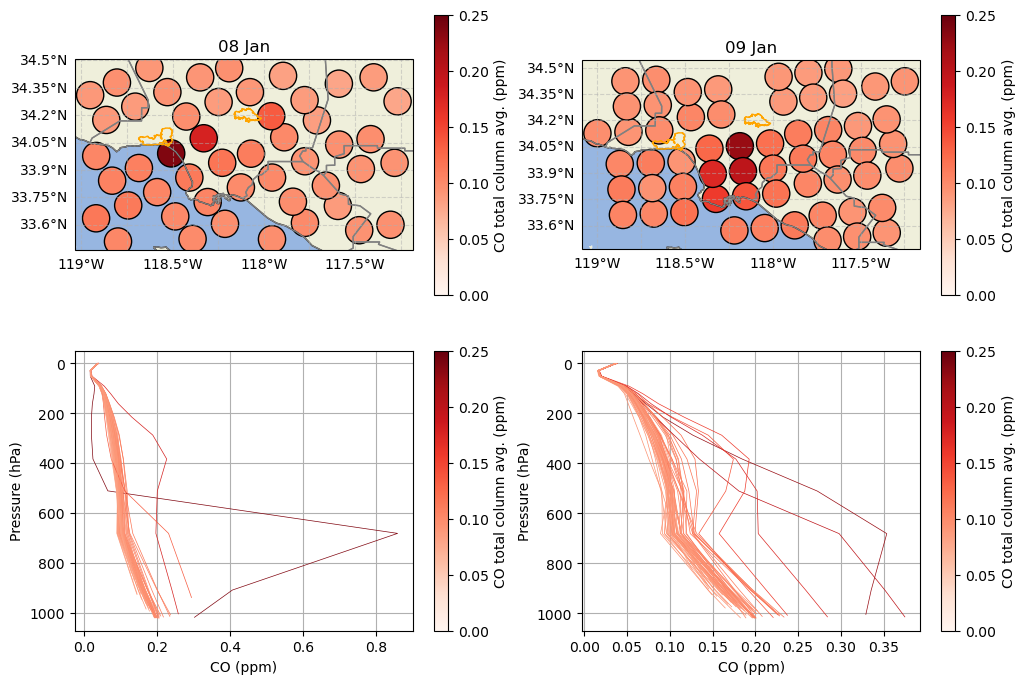

In [22]:
co_scatter_kws = dict(
    column='total',
    col_avg=True,
    vscale=1e6,
    vmin=0, vmax=0.25,
    cmap='Reds',
    cblabel='CO total column avg. (ppm)'
)

fig = plt.figure(figsize=(12,8))
gs = GridSpec(2, 2)
dates = pd.date_range('2025-01-08', '2025-01-09')

for idate, date in enumerate(dates):
    ax_map = fig.add_subplot(gs[0, idate], projection=ccrs.PlateCarree())
    nbplt.plot_muses_or_tropess_columns(
        data_root='static-data/tropess-daac/standard/', tropess_format=True,
        species='CO', date=date, extents=nbcst.LA_EXTENT, ax=ax_map, **co_scatter_kws
    )
    ax_map.set_title(f'{date:%d %b}')
    nbpu.add_fire_perimeter(
        ax_map, 'static-data/fire-progression/fire-perimeters.geojson',
        'palisades', edgecolor='orange', facecolor='none'
    )
    nbpu.add_fire_perimeter(
        ax_map, 'static-data/fire-progression/fire-perimeters.geojson',
        'eaton', edgecolor='orange', facecolor='none'
    )

    ax_prof = fig.add_subplot(gs[1, idate])
    plot_tropess_profile_ensemble(
        'CO', date, nbcst.LA_EXTENT, cmap='Reds',
        vscale=1e6, vmin=co_scatter_kws['vmin'], vmax=co_scatter_kws['vmax'],
        units='ppm', ax=ax_prof
    )
plt.savefig('figures/tropess-co-profiles.pdf', bbox_inches='tight')

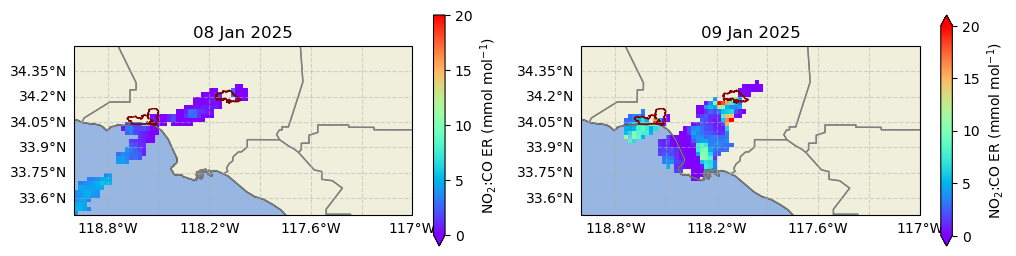

In [80]:
dates = pd.date_range('2025-01-08', '2025-01-09')

n = dates.size
_, axs = plt.subplots(1, n, figsize=(6*n, 3), subplot_kw={'projection': ccrs.PlateCarree()})

for ax, date in zip(axs, dates):
    nbplt.plot_gridded_enhancement(
        'static-data/tropomi-custom/tropess-dco-ratio/ratio-0.01000/enhancements/enhancement_eaton_and_palisades.nc',
        date=date,
        variable='Time/enhancement_ratio',
        extent=nbcst.LA_EXTENT,
        vmin=0, vmax=20, cmap='rainbow',
        plume_mask=LA_CUSTOM_PLUME_MASK,
        cblabel='NO$_2$:CO ER (mmol mol$^{{-1}}$)',
        show_mean_er=False,
        feature_kws={'land': True, 'ocean': True}, ax=ax
    )
    ax.set_title(date.strftime('%d %b %Y'))
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'palisades', edgecolor='maroon', facecolor='none'
    )
    nbpu.add_fire_perimeter(
        ax, 'static-data/fire-progression/fire-perimeters.geojson',
        'eaton', edgecolor='maroon', facecolor='none'
    )
plt.savefig('figures/tropomi-custom-ers.pdf', bbox_inches='tight')

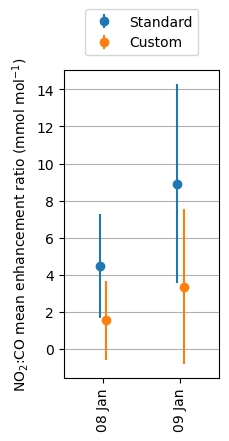

In [24]:
dates = pd.date_range('2025-01-08', '2025-01-09')

_, ax = plt.subplots(figsize=(2,4))

plot_mean_ers_for_dates(
    'static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc',
    dates,
    x_offset=pd.Timedelta(minutes=-60),
    plume_mask=LA_PLUME_MASK,
    extent=nbcst.LA_EXTENT,
    label='Standard',
    ax=ax
)

plot_mean_ers_for_dates(
    'static-data/tropomi-custom/tropess-dco-ratio/ratio-0.01000/enhancements/enhancement_eaton_and_palisades.nc',
    dates,
    x_offset=pd.Timedelta(minutes=60),
    plume_mask=LA_CUSTOM_PLUME_MASK,
    extent=nbcst.LA_EXTENT,
    label='Custom',
    ax=ax
)

ax.set_xlim(pd.Timestamp(2025,1,7,12), pd.Timestamp(2025,1,9,12))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.025))
plt.savefig('figures/tropomi-std-vs-custom-ers.pdf', bbox_inches='tight')

## NH3 plumes

In [25]:
def make_standard_nh3_plot(axs=None, vmax=7.5):
    if axs is None:
        _, axs = plt.subplots(1, 2, figsize=(12,3), subplot_kw={'projection': ccrs.PlateCarree()})

    for ax, day in zip(axs, [8,9]):
            nbplt.plot_muses_or_tropess_columns(
                data_root='static-data/tropess-daac/summary/',
                tropess_format=True,
                species='NH3',
                date=pd.Timestamp(2025,1,day),
                col_avg=True, vscale=1e9, cblabel='XNH$_3$ (ppb)',
                extents=nbcst.LA_EXTENT,
                cmap='Reds', vmin=0.0, vmax=vmax, ax=ax
            )
            ax.set_title(f'Jan {day}, standard')

    jplt.label_subplots(axs.flatten(), xpos=-0.025, ypos=1.05,)


def make_custom_nh3_plot(axs=None, vmax=7.5):
    if axs is None:
        _, axs = plt.subplots(1, 2, figsize=(12,3), subplot_kw={'projection': ccrs.PlateCarree()})

    for ax, day in zip(axs, [8,9]):
            _plot_one_nh3(
                tropess_file=f'static-data/tropess/custom-nh3/summary/NH3/2025-01-{day:02d}_TROPESS_CrIS-SNPP_L2_Summary_NH3_20260212_MUSES_R1p17_SC_BOX_F0p1_J0-1.nc',
                use_plume_ratio=True,
                vscale=1e9, extents=nbcst.LA_EXTENT, cblabel='XNH$_3$ (ppb)',
                cmap='Reds', vmin=0.0, vmax=vmax, ax=ax
            )
            ax.set_title(f'Jan {day}, custom')

    jplt.label_subplots(axs.flatten(), xpos=-0.025, ypos=1.025,)


def make_combined_nh3_plot(std_vmax=7.5, custom_vmax=7.5):
    _, axs = plt.subplots(2, 2, figsize=(12,6), subplot_kw={'projection': ccrs.PlateCarree()})
    make_standard_nh3_plot(axs=axs[0], vmax=std_vmax)
    make_custom_nh3_plot(axs=axs[1], vmax=custom_vmax)
    

def _plot_one_nh3(tropess_file, use_plume_ratio=False, vscale=1.0, extents=None, cblabel='', day_only=True, ax=None, **scatter_kws):
    data = _load_tropess_nh3(tropess_file, day_only, use_plume_ratio)
    if ax is None:
        _, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})

    scatter_kws.setdefault('s', 384)
    scatter_kws.setdefault('edgecolor', 'k')
    h = ax.scatter(data['lon'], data['lat'], c=data['xcol'] * vscale, **scatter_kws)
    plt.colorbar(h, ax=ax, label=cblabel)
    nbplt.add_features(ax, land=True, ocean=True)
    if extents is not None:
        ax.set_extent(extents)
        

def _load_tropess_nh3(tropess_file, day_only: bool, use_plume_ratio: bool):
    with Dataset(tropess_file) as ds:
        data = {
            'lon': ds['longitude'][:],
            'lat': ds['latitude'][:],
            'xcol': ds['col'][:] / ds['col_dry_air'][:]
        }

        if use_plume_ratio:
            # This is a fill when CO is too small to reliably determine the plume vertical shape
            print('Scaling by ratio_plume')
            ratio = ds['ratio_plume'][:].filled(1.0)
            data['xcol'] *= ratio

        if day_only:
            xx = ds['geophysical/day_night_flag'][:] == 1
            data = {k: v[xx] for k, v in data.items()}

        return data

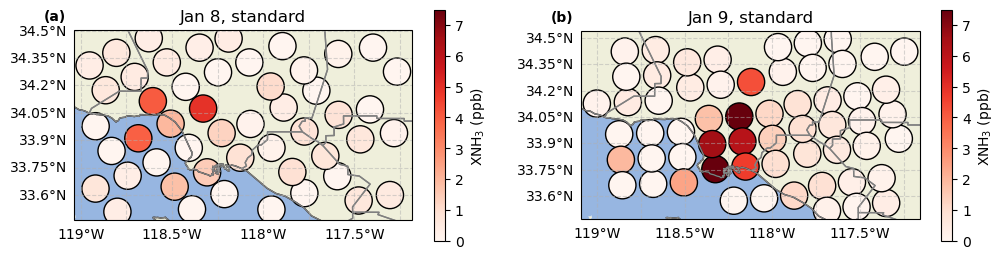

In [26]:
make_standard_nh3_plot()
plt.savefig('figures/tropess-std-nh3.pdf', bbox_inches='tight')

Scaling by ratio_plume
Scaling by ratio_plume


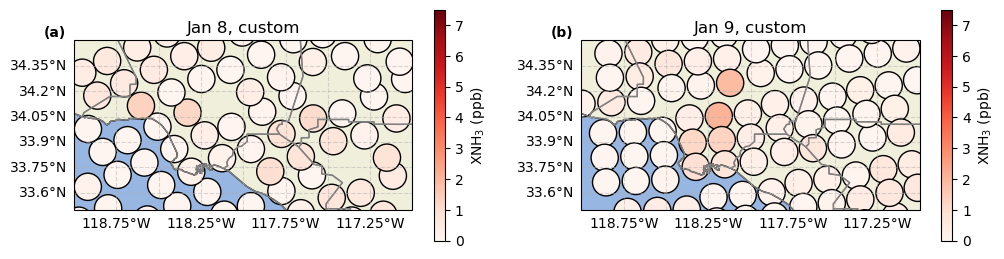

In [27]:
make_custom_nh3_plot()
plt.savefig('figures/tropess-custom-nh3.pdf', bbox_inches='tight')

## Fire progression

First, reproduce the VIIRS JPSS-2 multi-panel figure from the Nov workshop. Then work on a figure that shows a timeseries of FRP/fire counts from GOES, MODIS, and VIIRS in Altadena and outside. Will need to figure out how to make the box based on destroyed structures.

In [28]:
def make_frp_altadena_timeseries_with_maps(
    goes_frp: nberf.FrpProvider, modis_terra_frp: nberf.FrpProvider, viirs_jpss2_frp: nberf.FrpProvider,
    structure_dmg: gpd.GeoDataFrame, perimeter: gpd.GeoDataFrame,
    map_min_time='2025-01-07 12:00', map_max_time='2025-01-10 00:00',
    timeseries_min='2025-01-07', timeseries_max='2025-01-10',
):
    modis_df = modis_terra_frp.detection_df()
    viirs_df = viirs_jpss2_frp.detection_df()

    modis_df = modis_df[(modis_df.datetime > map_min_time) & (modis_df.datetime < map_max_time)]
    viirs_df = viirs_df[(viirs_df.datetime > map_min_time) & (viirs_df.datetime < map_max_time)]

    polys = _altadena_structure_perimeter(structure_dmg)
    altadena_rect = Polygon(miscutils.polygon_to_rect(polys[0]))

    fig_and_ax = _setup_frp_altadena_axes(modis_df, viirs_df)
    ax = fig_and_ax['timeseries']
    _, _, ax2 = jplt.create_twin_axes_with_color(color2='gray', ax=ax)
    handles = []
    handles.extend(
        nbplt.plot_frp_timeseries(goes_frp, min_time=timeseries_min, max_time=timeseries_max, bounds=altadena_rect,
                                  color='black', marker='o', label='Altadena', ax=ax)
    )
    handles.extend(
        nbplt.plot_frp_timeseries(goes_frp, min_time=timeseries_min, max_time=timeseries_max,
                                  bounds=nbutils.extents_to_polygon(nbcst.EATON_EXTENT), color='gray',
                                  marker='.', label='Full Eaton fire', ax=ax2)
    )
    ax.legend(handles=handles, ncols=2)
    ax.grid(axis='y')
    ax2.grid(False)
    ax.xaxis.set_major_locator(mdates.HourLocator([0,6,12,18]))

    _add_frp_maps(
        fire_df=viirs_df,
        structure_df=structure_dmg,
        perimeter_df=perimeter,
        axs=fig_and_ax['viirs'],
        colors=fig_and_ax['viirs_colors'],
        timeseries_ax=ax,
        fig=fig_and_ax['fig'],
        sat='VIIRS (JPSS-2)',
        label_lons=False
    )

    struct_h = _add_frp_maps(
        fire_df=modis_df,
        structure_df=structure_dmg,
        perimeter_df=perimeter,
        axs=fig_and_ax['modis'],
        colors=fig_and_ax['modis_colors'],
        timeseries_ax=ax,
        fig=fig_and_ax['fig'],
        sat='MODIS (Terra)',
        label_lons=True,
    )
    plt.colorbar(struct_h, cax=fig_and_ax['cb'], label='# structures destroyed')


def _altadena_structure_perimeter(structure_dmg: gpd.GeoDataFrame,):
    h, x, y = nbstruct.make_structure_damage_2d_hist(structure_dmg, extent=nbcst.ALTADENA_EXTENT)
    m = miscutils.flood_fill_at_coords(h, x, y, -118.15, 34.195, 20)
    return miscutils.extract_polygon_from_mask(m, x, y)
    

def _setup_frp_altadena_axes(modis_df, viirs_df):
    n = modis_df.overpass_index.unique().size
    if n != viirs_df.overpass_index.unique().size:
        raise NotImplementedError('Different numbers of MODIS and VIIRS overpasses')

    colors = plt.get_cmap('tab10')
    modis_colors = [colors(i) for i in range(n)]
    viirs_colors = [colors(i) for i in range(n, 2*n)]
    
    fig = plt.figure(figsize=(12,6))
    wr = [10] * n + [1]
    gs = GridSpec(nrows=3, ncols=n+1, height_ratios=[1,1,3], hspace=0.4, width_ratios=wr)
    modis_axs = [fig.add_subplot(gs[0,i], projection=ccrs.PlateCarree()) for i in range(n)]
    for i, ax in enumerate(modis_axs):
        for spine in ax.spines.values():
            spine.set_color(modis_colors[i])
    viirs_axs = [fig.add_subplot(gs[1,i], projection=ccrs.PlateCarree()) for i in range(n)]
    for i, ax in enumerate(viirs_axs):
        for spine in ax.spines.values():
            spine.set_color(viirs_colors[i])
    timeseries_ax = fig.add_subplot(gs[2,:])
    cb_ax = fig.add_subplot(gs[:2, -1])
    return {
        'fig': fig,
        'modis': modis_axs,
        'modis_colors': modis_colors,
        'viirs': viirs_axs,
        'viirs_colors': viirs_colors,
        'timeseries': timeseries_ax,
        'cb': cb_ax
    }


def _add_frp_maps(fire_df, structure_df, perimeter_df, axs, timeseries_ax, fig, colors, sat, label_lons):
    n = fire_df.overpass_index.unique().size
    x = np.linspace(0, 1, num=n+1)[:n]
    width = 1 / n * 0.96
    
    for i, (_, overpass_df) in enumerate(fire_df.groupby('overpass_index')):
        ax = axs[i]
        struct_h = nbstruct.plot_structures_hist(structure_df, extent=nbcst.ALTADENA_EXTENT, add_colorbar=False, ax=ax)
        nbstruct.plot_final_perimeter(perimeter_df, 'eaton', ax=ax)
        ax.plot(overpass_df.longitude, overpass_df.latitude, color='red', ls='none', marker='.', markersize=2)
        
        ax.set_extent(nbcst.EATON_EXTENT)
        start = overpass_df.datetime.min().tz_convert('-08:00').tz_localize(None)
        ax.set_title(f'{sat}\n{start:%d %b %H:%M} PST', fontsize=8, color=colors[i])
        gl = ax.gridlines(draw_labels=True)
        gl.right_labels = False
        gl.bottom_labels = False
        if i > 0:
            gl.left_labels = False
        if not label_lons:
            gl.top_labels = False

        timeseries_ax.axvline(start, ls='--', color=colors[i])

        patch = ConnectionPatch(
            xyA=[start.tz_localize(None), timeseries_ax.get_ylim()[1]],
            xyB=[0.5, 0],
            coordsA='data',
            coordsB=ax.transAxes,
            axesA=timeseries_ax,
            axesB=ax,
            color=colors[i],
            zorder=0
        )
        fig.add_artist(patch)
    return struct_h

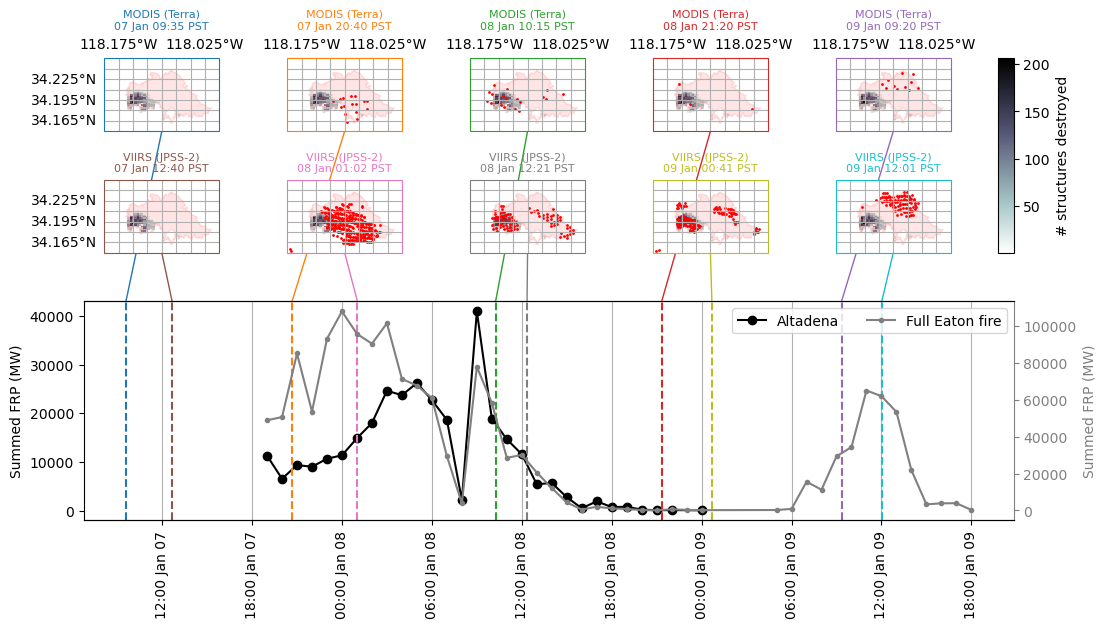

In [29]:
make_frp_altadena_timeseries_with_maps(GOES_FRP_LA_ONLY, MODIS_TERRA_FRP, VIIRS_JPSS2_FRP, STRUCTURE_DAMAGE_GDF, PERIMETERS_GDF)
plt.savefig('figures/eaton-fire-progression.pdf', bbox_inches='tight')

## Topography and fire progression

In [14]:
def make_topography_land_cover_fire_progression_plot(
    structure_gdf: gpd.GeoDataFrame,
    perimeters_gdf: gpd.GeoDataFrame,
    viirs_frp: nberf.FrpProvider,
):
    fig = plt.figure(figsize=(6,12))
    gs = GridSpec(3, 2, width_ratios=[20,1])

    full_peri_color = 'black'
    full_peri_ls = ':'
    altadena_peri_color = 'black'
    altadena_peri_ls = '-.'

    all_axs = []
    ax = fig.add_subplot(gs[0,0], projection=ccrs.PlateCarree())
    all_axs.append(ax)
    ax0 = ax
    
    
    hstruct = nbstruct.plot_altadena_structure_perimeter(structure_gdf, ax=ax, facecolor='none', edgecolor=altadena_peri_color, ls=altadena_peri_ls, alpha=1, zorder=9)
    hfire = nbstruct.plot_final_perimeter(perimeters_gdf, name='eaton', ax=ax, facecolor='none', edgecolor=full_peri_color, ls=full_peri_ls, alpha=1, zorder=10)
    hfrp = plot_frps_colored_by_overpass(
        viirs_frp.detection_df(),
        pd.Timestamp(2025,1,8, tz='-08:00'),
        pd.Timestamp(2025,1,9,18, tz='-08:00'),
        extent=nbcst.EATON_EXTENT, ax=ax
    )

    handles = [hstruct, hfire] + hfrp
    ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.025, 0.5), ncols=1)
    gl = ax.gridlines(draw_labels=True)
    gl.right_labels = False
    gl.top_labels = False
    
    ax = fig.add_subplot(gs[1,0], projection=ccrs.PlateCarree(), sharex=ax0, sharey=ax0)
    all_axs.append(ax)
    cax = fig.add_subplot(gs[1,1])
    plot_nasadem_topo(extent=nbcst.EATON_EXTENT, ax=ax, cax=cax)
    nbstruct.plot_altadena_structure_perimeter(structure_gdf, ax=ax, facecolor='none', edgecolor=altadena_peri_color, ls=altadena_peri_ls, alpha=1, zorder=9)
    nbstruct.plot_final_perimeter(perimeters_gdf, name='eaton', ax=ax, facecolor='none', edgecolor=full_peri_color, ls=full_peri_ls, alpha=1, zorder=10)

    ax = fig.add_subplot(gs[2,0], projection=ccrs.PlateCarree(), sharex=ax0, sharey=ax0)
    all_axs.append(ax)
    cax = fig.add_subplot(gs[2,1])
    plot_nlcd([ax, cax], extent=nbcst.EATON_EXTENT)
    nbstruct.plot_altadena_structure_perimeter(structure_gdf, ax=ax, facecolor='none', edgecolor=altadena_peri_color, ls=altadena_peri_ls, alpha=1, zorder=9)
    nbstruct.plot_final_perimeter(perimeters_gdf, name='eaton', ax=ax, facecolor='none', edgecolor=full_peri_color, ls=full_peri_ls, alpha=1, zorder=10)

    jplt.label_subplots(all_axs, xpos=-0.025)

def plot_nasadem_topo(ax=None, add_cb=True, extent=None, dem_file='static-data/topography/socal_nasadem.tif', cax=None, **pcolor_kws):
    if ax is None:
        _, ax = plt.subplots(figsize=(6,3), subplot_kw={'projection': ccrs.PlateCarree()})

    with rasterio.open(dem_file) as tiff:
        data = np.ma.masked_equal(tiff.read(), tiff.nodata)[0]
        data_crs = ccrs.Projection(tiff.crs)

        cols = np.arange(tiff.width)
        rows = np.arange(tiff.height)
        x_coords, _ = tiff.transform * (cols + 0.5, np.zeros_like(cols))
        _, y_coords = tiff.transform * (np.zeros_like(rows), rows + 0.5)

    
    if extent is not None:
        x1, x2, y1, y2 = extent
        xx = (x_coords >= x1) & (x_coords <= x2)
        yy = (y_coords >= y1) & (y_coords <= y2)
        x_coords = x_coords[xx]
        y_coords = y_coords[yy]
        data = data[yy][:, xx]

    vmin = pcolor_kws.pop('vmin', 0)
    vmax = pcolor_kws.pop('vmax', 2000)
    pcolor_kws.setdefault('cmap', 'terrain')
    pcolor_kws.setdefault('norm', jplt.TerrainNorm(vmin=vmin, vmax=vmax))
    h = ax.pcolormesh(x_coords, y_coords, data, transform=data_crs, **pcolor_kws)
    if cax is None:
        plt.colorbar(h, ax=ax, label='Elevation (m)')
    else:
        plt.colorbar(h, cax=cax, label='Elevation (m)')
    gl = ax.gridlines(draw_labels=True)
    gl.right_labels = False
    gl.top_labels = False

def plot_frps_colored_by_overpass(frp_df, min_time, max_time, cmap='Set2', extent=None, ax=None):
    tt = (frp_df.datetime >= min_time) & (frp_df.datetime <= max_time)
    frp_df = frp_df.loc[tt, :]
    colors = plt.get_cmap(cmap)
    markers = '.+^x'

    if ax is None:
        _, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})

    handles = []
    for i_overpass, (_, overpass_df) in enumerate(frp_df.groupby('overpass_index')):
        color = colors(i_overpass)
        start = overpass_df.datetime.min().tz_convert('-08:00').tz_localize(None)
        label = f'VIIRS FRP, {start:%d %b %H:%M} PST'
        h = ax.plot(overpass_df.longitude, overpass_df.latitude, marker=markers[i_overpass], color=color,
                    ls='none', label=label)
        handles.extend(h)
    if extent is not None:
        ax.set_extent(extent)
    return handles


def plot_nlcd(
    axs=None,
    land_cover_file='static-data/land-cover/nlcd/Annual_NLCD_LndCov_2024_CU_C1V1_5f9a5cb2-3017-4659-bef5-a8ebc7edc805.tiff',
    definition_file='static-data/land-cover/nlcd/NLCD_landcover_layer_2018_12_17_5f9a5cb2-3017-4659-bef5-a8ebc7edc805.csv',
    extent=None,
):
    with rasterio.open(land_cover_file) as tiff:
        data = np.ma.masked_equal(tiff.read(), tiff.nodata)[0]
        data_crs = ccrs.Projection(tiff.crs)

        cols = np.arange(tiff.width)
        rows = np.arange(tiff.height)
        x_coords, _ = tiff.transform * (cols + 0.5, np.zeros_like(cols))
        _, y_coords = tiff.transform * (np.zeros_like(rows), rows + 0.5)

    if extent is not None:
        data, x_coords, y_coords = _subset_tiff_to_extent(extent, x_coords, y_coords, data, data_crs)

    definition_df = pd.read_csv(definition_file).dropna().set_index('Value')
    data, definition_df = _remap_nlcd_values(data, definition_df)
    
    if axs is None:
        fig = plt.figure(figsize=(6,4))
        gs = GridSpec(1, 2, width_ratios=[20,1])
        ax = fig.add_subplot(gs[0], projection=ccrs.PlateCarree())
        cax = fig.add_subplot(gs[1])
    else:
        ax, cax = axs

    n_categories = definition_df.shape[0]
    cmap = Colormap('tol:rainbow_discrete_14').to_mpl()
    norm = jplt.discrete_norm(definition_df.index.to_numpy(), cmap)
    h = ax.pcolormesh(x_coords, y_coords, data, transform=data_crs, cmap=cmap, norm=norm)
    cb = plt.colorbar(h, cax=cax)
    cb.set_ticks(definition_df.index)
    cb.set_ticklabels(definition_df.Legend.to_list())

    if extent is not None:
        ax.set_extent(extent)
    gl = ax.gridlines(draw_labels=True)
    gl.right_labels = False
    gl.top_labels = False


def _remap_nlcd_values(map_array, definition_df):
    old_indices = np.unique(map_array)
    if np.ndim(old_indices.mask) > 0:
        # Protect against a mask of np.False_
        old_indices = old_indices[~old_indices.mask]
    
    new_indices = np.arange(old_indices.size)
    new_legend = []
    new_map = np.full(map_array.shape, -999)
    for old_index, new_index in zip(old_indices, new_indices):
        new_legend.append(definition_df.loc[old_index, 'Legend'])
        new_map[map_array == old_index] = new_index
    new_map = np.ma.masked_less(new_map, 0)
    return new_map, pd.DataFrame({'Legend': new_legend}, index=new_indices)


def _subset_tiff_to_extent(extent, x_coords, y_coords, data: np.ma.MaskedArray, data_crs, mask_outside: bool = True):
    x1, x2, y1, y2 = extent
    dx = x2 - x1
    dy = y2 - y1
    x1a = x1 - dx
    x2a = x2 + dx
    y1a = y1 - dy
    y2a = y2 + dy

    # Broadly cut down the data using a bounding box thrice as large
    # as the extent, assuming that will be enough that setting the
    # extent later won't have any removed data
    x1a, y1a = data_crs.transform_point(x1a, y1a, ccrs.PlateCarree())
    x2a, y2a = data_crs.transform_point(x2a, y2a, ccrs.PlateCarree())
    xxa = (x_coords >= x1a) & (x_coords <= x2a)
    yya = (y_coords >= y1a) & (y_coords <= y2a)
    x_coords = x_coords[xxa]
    y_coords = y_coords[yya]
    data = data[yya][:, xxa]

    if mask_outside:
        all_x, all_y = np.meshgrid(x_coords, y_coords)
        assert all_x.shape == data.shape
        assert all_y.shape == data.shape
        lonlat = ccrs.PlateCarree().transform_points(data_crs, all_x.ravel(), all_y.ravel())
        all_lon = lonlat[:,0].reshape(data.shape)
        all_lat = lonlat[:,1].reshape(data.shape)
        is_outside = (all_lon < x1) | (all_lon > x2) | (all_lat < y1) | (all_lat > y2)
        data = np.ma.masked_where(is_outside, data)

    return data, x_coords, y_coords

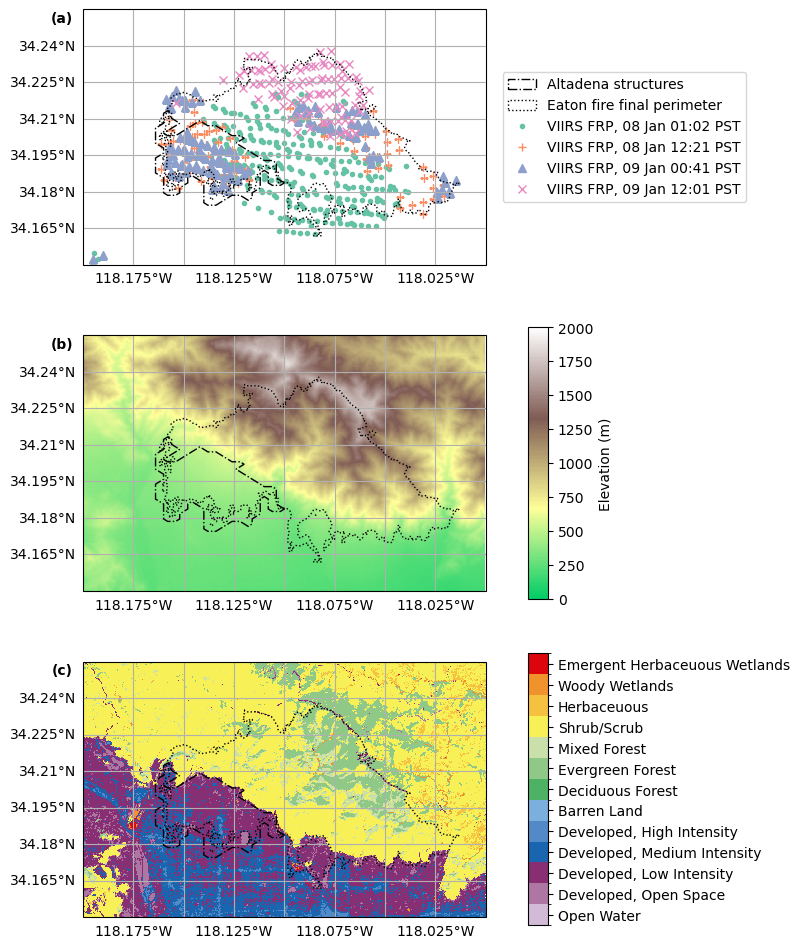

In [15]:
make_topography_land_cover_fire_progression_plot(STRUCTURE_DAMAGE_GDF, PERIMETERS_GDF, VIIRS_JPSS2_FRP)
plt.savefig('figures/eaton-fire-topography.pdf', bbox_inches='tight')
plt.savefig('figures/eaton-fire-topography.png', bbox_inches='tight')

## Aerosol properties

In [32]:
def make_no2_er_vs_aerosol_plots(plume_mask, dates=pd.date_range('2025-01-08', '2025-01-09')):

    aer_kws = {'scene': 'eaton_and_palisades', 'plume_mask': plume_mask, 'extent': nbcst.LA_EXTENT}
    aer_values = {
        'AOD (unitless)': partial(nbaer.load_aerosol_variable_for_date, quantity='aer', variable='aod', **aer_kws),
        'SSA (unitless)': partial(nbaer.load_aerosol_variable_for_date, quantity='aer', variable='ssa', **aer_kws),
        'ALH (m)': partial(nbaer.load_variable_for_date, quantity='alh', variable='alh', **aer_kws),
    }

    gas_values = {
        'NO$_2$ trop. col. (mol m$^{-2}$)': partial(
            nbgrid.load_variable_for_date,
            quantity='no2',
            scene='eaton_and_palisades',
            variable='no2_trop',
            plume_mask=plume_mask,
            extent=nbcst.LA_EXTENT,
        ),

        'NO$_2$:CO ER (mmol mol$^{-1}$)': partial(
            nber.load_enhancements_for_date,
            grid_file='static-data/tropomi/enhancements/enhancement_eaton_and_palisades.nc',
            variable='Time/enhancement_ratio',
            plume_mask=plume_mask,
            extent=nbcst.LA_EXTENT,
        )
    }

    with plt.rc_context({'axes.formatter.limits': (-2,3), 'axes.formatter.use_mathtext': True}):
        nx = len(aer_values)
        ny = len(gas_values)
        _, axs = plt.subplots(ny, nx, figsize=(nx*4, ny*4), sharex='col', sharey='row')
    
        colors = plt.get_cmap('tab10')
        
        for ax_row, (gas_label, gas_fxn) in zip(axs, gas_values.items()):
            for ax, (aer_label, aer_fxn) in zip(ax_row, aer_values.items()):
                for idate, date in enumerate(dates):
                    aer_data = aer_fxn(date=date)
                    gas_data = gas_fxn(date=date)
                    assert np.allclose(aer_data['lon'], gas_data['lon']), 'lon grids do not match'
                    assert np.allclose(aer_data['lat'], gas_data['lat']), 'lat grids do not match'
    
                    ii = np.isfinite(aer_data['values'].filled(np.nan)) & np.isfinite(gas_data['values'].filled(np.nan))
                    ax.plot(aer_data['values'][ii], gas_data['values'][ii], ls='none', marker='.', color=colors(idate), label=date.strftime('%d %b'))
                ax.set_xlabel(aer_label)
                ax.set_ylabel(gas_label)
                ax.grid(True)
    
        axs[0, nx // 2].legend(ncols=2, loc='lower center', bbox_to_anchor=(0.5, 1.025))
        for ax in axs[:, 1:].flat:
            ax.set_ylabel('')
        for ax in axs[:-1].flat:
            ax.set_xlabel('')
        jplt.label_subplots(axs.flatten(), xpos=0.1, ypos=0.94)

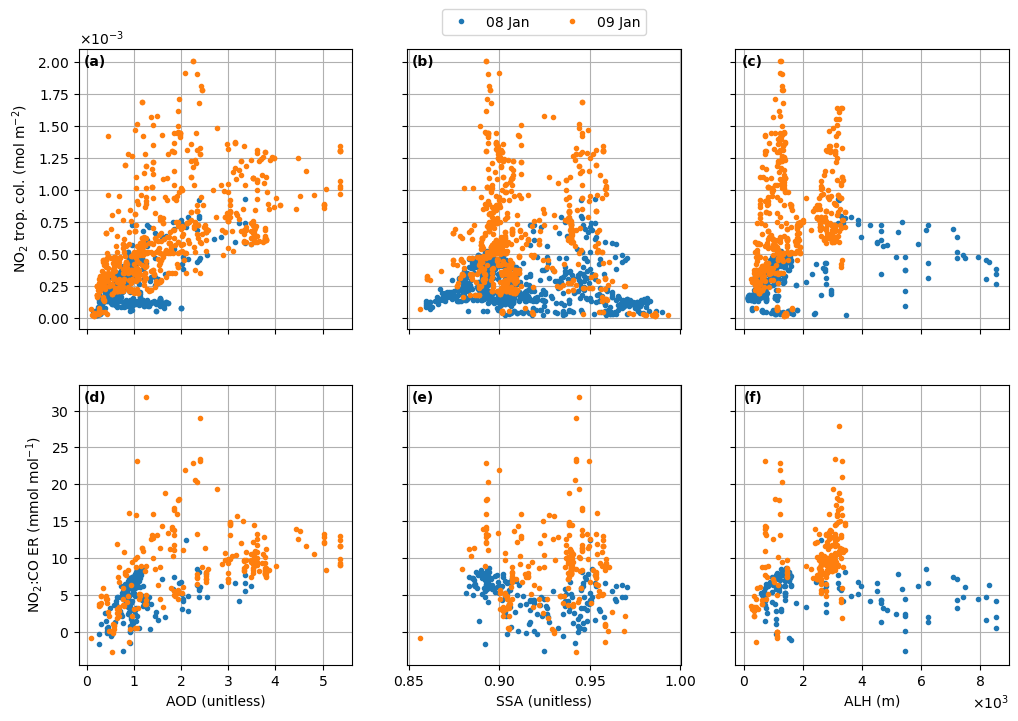

In [33]:
make_no2_er_vs_aerosol_plots(LA_PLUME_MASK)
plt.savefig('figures/tropomi-aerosol-properties.pdf', bbox_inches='tight')

## NO:NO$_2$ ratio

In [116]:
CARB_NOX.date[CARB_NOX.date.dt.year == 2021].max()

Timestamp('2021-09-15 23:00:00')

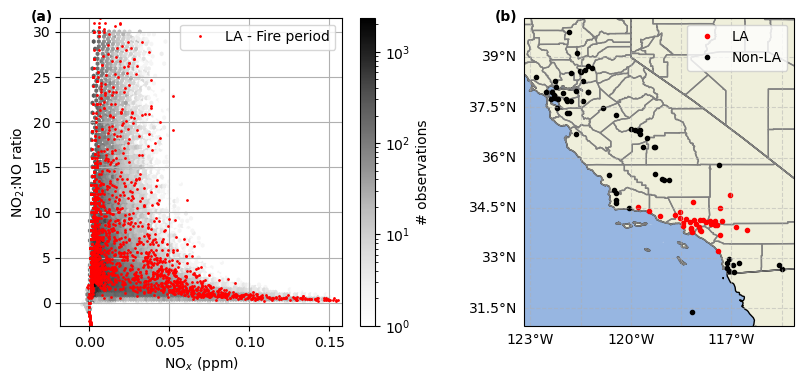

In [123]:
fig = plt.figure(figsize=(10,4))
all_axs = []
ax = fig.add_subplot(1, 2, 1)
all_axs.append(ax)

nbcarb.plot_carb_ratio_vs_nox(CARB_NOX, extent=[-0.01, 0.15, -1, 30], ax=ax)
ax.set_xlim(ax.get_xlim())
ax.set_ylim(ax.get_ylim())
la_extent = [-120, -115, 33, 35]
nbcarb.plot_carb_ratio_vs_nox_subset(
    CARB_NOX,
    time_extent=[pd.Timestamp(2025,1,7,tz='-08:00'), pd.Timestamp(2025,1,11,tz='-08:00')],
    spatial_extent=la_extent,
    markersize=2, label='LA - Fire period',
    ax=ax
)
ax.legend(loc='upper right')

ax = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
all_axs.append(ax)

for (y, x), _ in CARB_NOX.groupby(['latitude', 'longitude']):
    color = 'red' if (x >= la_extent[0]) and (x <= la_extent[1]) and (y >= la_extent[2]) and (y <= la_extent[3]) else 'black'
    ax.plot(x, y, marker='.', color=color)
nbplt.add_features(ax, land=True, ocean=True)
ax.legend(
    handles=[
        mlines.Line2D([0], [0], color='red', marker='.', ls='none', label='LA'),
        mlines.Line2D([0], [0], color='black', marker='.', ls='none', label='Non-LA'),
    ]
)

jplt.label_subplots(all_axs, xpos=-0.025, ypos=0.99)

plt.savefig('figures/carb-no2-to-no.pdf', bbox_inches='tight')

## Ozone titration plots

In [85]:
def make_o3_titration_plot(perimeter_df: gpd.GeoDataFrame):
    o3_scatter_kws = dict(
        column='trop',
        col_avg=True,
        vscale=1e9,
        vmin=40, vmax=80,
        cmap='PuRd',
        cblabel='Trop. XO$_3$ (ppb)',
        s=64,
    )
    extents = [-120, -116, 32, 36]
    ts_dates = pd.date_range('2025-01-01', '2025-01-10')
    dates = pd.date_range('2025-01-07', '2025-01-09')
    nx = len(dates)
    fig = plt.figure(figsize=(12,6))
    gs = GridSpec(nrows=4, ncols=nx+1, width_ratios=[2]*nx + [1], height_ratios=[7.5, 1, 10, 1], wspace=0.4)
    
    
    box_lon, box_lat = nbutils.default_upwind_box()
    box_poly = nbutils.default_upwind_box(as_poly=True)
    box_mean_xo3 = np.full(dates.shape, np.nan)
    box_sigma_xo3 = np.full(dates.shape, np.nan)

    extents_poly = nbutils.extents_to_polygon(extents)
    ts_mean_xo3 = np.full(ts_dates.size, np.nan)
    ts_sigma_xo3 = np.full(ts_dates.size, np.nan)
    for i, date in enumerate(ts_dates):
        ts_mean_xo3[i], ts_sigma_xo3[i] = _compute_mean_col_in_box(
            box_poly=extents_poly, species='O3', date=date, column=o3_scatter_kws['column'], col_avg=o3_scatter_kws['col_avg']
        )
    ax = fig.add_subplot(gs[0, :])
    ax.errorbar(
        ts_dates, ts_mean_xo3 * o3_scatter_kws['vscale'], yerr=ts_sigma_xo3 * o3_scatter_kws['vscale'],
        marker='o', color='black'
    )
    ax.grid(True)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.set_ylabel('Tropospheric XO$_3$ (ppb)')

    cax = fig.add_subplot(gs[3, :nx])

    all_axs = [ax]

    
    for idate, date in enumerate(dates):
        ax = fig.add_subplot(gs[2, idate], projection=ccrs.PlateCarree())
        all_axs.append(ax)
        nbplt.plot_muses_or_tropess_columns(
            'static-data/tropess-daac/summary/',
            tropess_format=True,
            species='O3',
            date=date,
            extents=extents,
            ax=ax, cax=cax, no_colorbar=idate > 0, cbkw={'orientation': 'horizontal'},
            **o3_scatter_kws
        )
        nbpu.plot_box(box_lon, box_lat, ax=ax, color='green')
        nbstruct.plot_final_perimeter(perimeter_df, 'eaton', ax=ax, facecolor='none', edgecolor='darkred', alpha=1)
        ax.set_title(f'{date:%d %b}')

        box_mean_xo3[idate], box_sigma_xo3[idate] = _compute_mean_col_in_box(
            box_poly=box_poly, species='O3', date=date, column=o3_scatter_kws['column'], col_avg=o3_scatter_kws['col_avg']
        )

    ax = fig.add_subplot(gs[2, -1])
    all_axs.append(ax)
    ax.errorbar(dates, box_mean_xo3 * o3_scatter_kws['vscale'], yerr=box_sigma_xo3 * o3_scatter_kws['vscale'],
                ls='none', marker='o', color='green')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)
    ax.grid(axis='y')
    ax.set_xlim(dates[0] - pd.Timedelta(hours=12), dates[-1] + pd.Timedelta(hours=12))
    ax.set_ylabel('Tropospheric XO$_3$ (ppb)')
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    
    jplt.label_subplots(all_axs[:1], xpos=0.995, ypos=0.9, seq='a')
    jplt.label_subplots(all_axs[1:], xpos=0.975, ypos=0.92, seq='bcde')


def _compute_mean_col_in_box(box_poly, species, date, column, col_avg, debug_plot=False):
    data = nbtrdat.load_tropess_cols('static-data/tropess-daac/summary/', species, date)
    lon = data['lon']
    lat = data['lat']
    cols = nbtrdat.get_muses_col_values(data, column, col_avg)

    ii = nbtrdat.make_filter_index(data, extents=[-180, 180, -90, 90], good_only=False, day_only=True)
    lon = lon[ii]
    lat = lat[ii]
    cols = cols[ii]
    
    is_in = nbutils.in_poly(lon, lat, box_poly)
    mean_col = np.nanmean(cols[is_in])
    sigma_col = np.nanstd(cols[is_in])

    if debug_plot:
        _, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()})
        h = ax.scatter(lon[is_in], lat[is_in], c=cols[is_in])
        plt.colorbar(h, ax=ax)
        plot_box(*box_poly.exterior.xy, color='k')
        add_features(ax)
        return mean_col, sigma_col, ax
    else:
        return mean_col, sigma_col

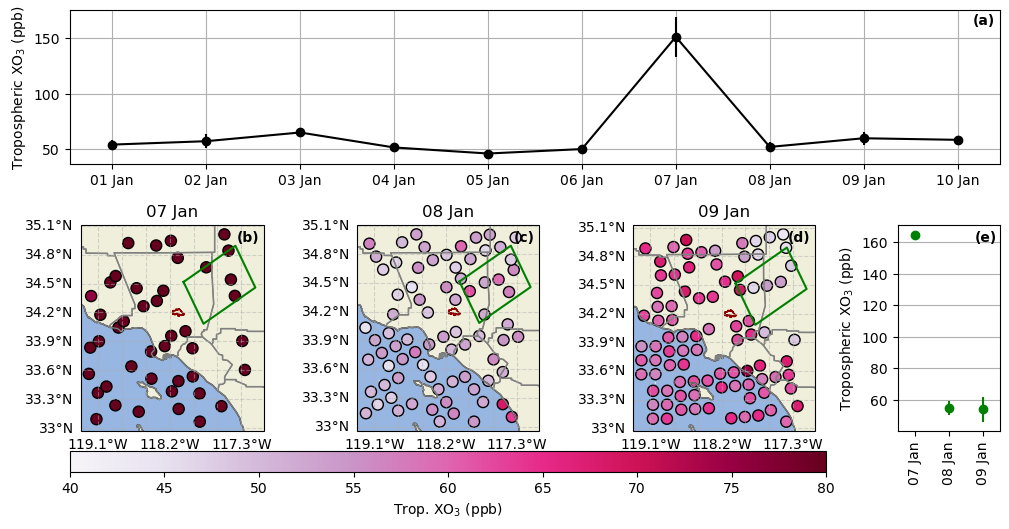

In [87]:
make_o3_titration_plot(PERIMETERS_GDF)
plt.savefig('figures/tropess-o3.png', bbox_inches='tight')

## FRP diurnal cycle

In [37]:
def make_frp_by_hour_plot(summed=False):
    anderson_fires_by_hour = nbplt.make_goes_frp_by_hour_df(GOES_WEST_COAST_FRP, ANDERSON_CFG['scene'])
    la_fires_by_hour = nbplt.make_goes_frp_by_hour_df(GOES_WEST_COAST_FRP, LA_CFG['scene'])
    
    _, ax = plt.subplots(figsize=(6,4))
    if summed:
        column = 'total_frp'
        ylabel = 'Summed FRP (MW)'
    else:
        column = 'mean_frp'
        ylabel = 'Mean FRP (MW)'
        
    nbplt.frp_by_hour_violins(anderson_fires_by_hour, column=column, ax=ax)
    nbplt.frp_by_hour_per_date(la_fires_by_hour, column=column, ax=ax)
    ax.legend(ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.025))
    ax.set_ylabel(ylabel)

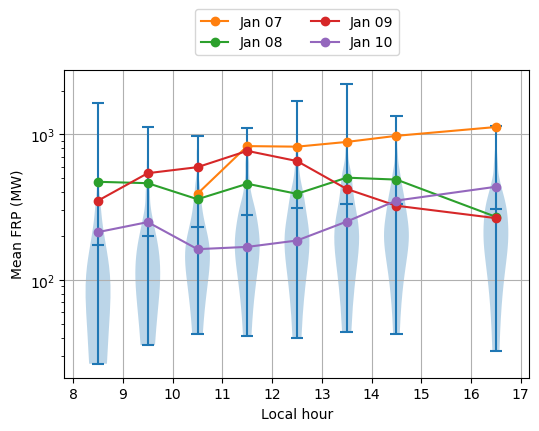

In [38]:
make_frp_by_hour_plot()
plt.savefig('figures/frp-diurnal-evolution.png', bbox_inches='tight')

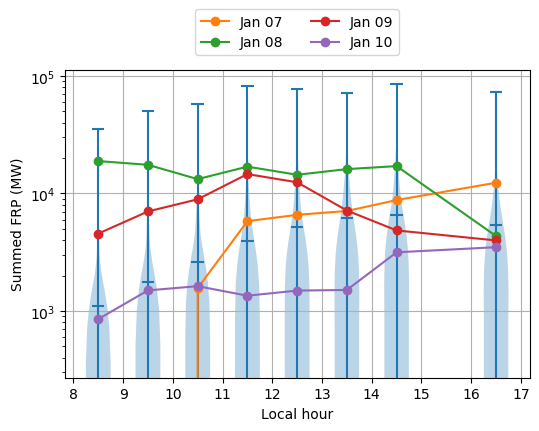

In [39]:
make_frp_by_hour_plot(summed=True)
plt.savefig('figures/frp-diurnal-evolution-summed.png', bbox_inches='tight')

## Comparison to previous fires

In [41]:
def make_er_vs_frp_plot(frp_col='mean_frp', include_custom: bool = False):
    west_coast_dfs, la_dfs = _prep_frp_er_dfs(include_custom)

    _, axs = plt.subplots(1, 3, figsize=(15,4), sharey=True)
    ax = axs[0]
    nbplt.fire_fit_plot(west_coast_dfs['VIIRS'], frp_col, ax=ax)
    _add_eaton_points(ax, la_dfs['VIIRS'], frp_col)
    _edit_er_vs_frp_xlabel(ax, 'VIIRS')
    # ax.text(0.98, 0.98, 'VIIRS', transform=ax.transAxes, ha='right', va='top')

    ax = axs[1]
    nbplt.fire_fit_plot(west_coast_dfs['GOES']['0900-1200'], frp_col, ax=ax)
    _add_eaton_points(ax, la_dfs['GOES']['0900-1200'], frp_col)
    _edit_er_vs_frp_xlabel(ax, 'GOES between 0900 & 1200')
    # ax.text(0.98, 0.98, 'GOES, 0900-1200', transform=ax.transAxes, ha='right', va='top')

    ax = axs[2]
    nbplt.fire_fit_plot(west_coast_dfs['GOES']['1200-1500'], frp_col, ax=ax)
    _add_eaton_points(ax, la_dfs['GOES']['1200-1500'], frp_col)
    _edit_er_vs_frp_xlabel(ax, 'GOES between 1200 & 1500')
    # ax.text(0.98, 0.98, 'GOES, 1200-1500', transform=ax.transAxes, ha='right', va='top')

    for ax in axs[1:]:
        ax.set_ylabel('')
    for ax in axs:
        ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0125))

    jplt.label_subplots(axs, xpos=0.075, ypos=0.96)


def _edit_er_vs_frp_xlabel(ax, desc):
    quantity, units = ax.get_xlabel().split('(')
    # the trailing parentheses is still on "units"
    ax.set_xlabel(f'{quantity.strip()} from {desc} ({units}')
    

def _add_eaton_points(ax, eaton_df_dict, frp_col):
    dates_colors = {
        '2025-01-08': 'tab:green',
        '2025-01-09': 'tab:purple'
    }
    markers = '^*Pv'
    for mkr, (case, eaton_df) in zip(markers, eaton_df_dict.items()):
        for date, color in dates_colors.items():
            date = pd.to_datetime(date)
            if case:
                label = f'LA, {date:%d %b} ({case})'
            else:
                label = f'LA, {date:%d %b}'
            ax.plot(eaton_df.loc[date, frp_col], eaton_df.loc[date, 'er'], marker=mkr, markersize=12,
                    ls='none', color=color, label=label)




def _prep_frp_er_dfs(include_custom: bool):
    west_coast_dfs = {'VIIRS': None, 'GOES': dict()}

    west_coast_dfs['VIIRS'] = nberf.match_frps_to_ers_many_files(
        frp=VIIRS_WEST_COAST_FRP,
        er=SLOPE_ER_PROVIDER,
        scenes=ANDERSON_CFG['scene'],
        local_hour_limits=(9, 15)
    )
    
    west_coast_dfs['GOES']['0900-1200'] = nberf.match_frps_to_ers_many_files(
        frp=GOES_WEST_COAST_FRP,
        er=SLOPE_ER_PROVIDER,
        scenes=ANDERSON_CFG['scene'],
        local_hour_limits=(9, 12)
    )
    
    west_coast_dfs['GOES']['1200-1500'] = nberf.match_frps_to_ers_many_files(
        frp=GOES_WEST_COAST_FRP,
        er=SLOPE_ER_PROVIDER,
        scenes=ANDERSON_CFG['scene'],
        local_hour_limits=(12, 15)
    )

    la_slope_dfs = {'VIIRS': dict(), 'GOES': dict()}

    la_slope_dfs['VIIRS']['std. NO$_2$'] = nberf.match_frps_to_ers_many_files(
        VIIRS_JPSS2_FRP,
        LA_SLOPE_ER,
        scenes=LA_CFG['scene'],
        local_hour_limits=(9,15)
    )

    la_slope_dfs['GOES']['0900-1200'] = dict()
    la_slope_dfs['GOES']['1200-1500'] = dict()
    la_slope_dfs['GOES']['0900-1200']['std. NO$_2$'] = nberf.match_frps_to_ers_many_files(
        GOES_WEST_COAST_FRP,
        LA_SLOPE_ER,
        scenes=LA_CFG['scene'],
        local_hour_limits=(9,12)
    )
    
    la_slope_dfs['GOES']['1200-1500']['std. NO$_2$'] = nberf.match_frps_to_ers_many_files(
        GOES_WEST_COAST_FRP,
        LA_SLOPE_ER,
        scenes=LA_CFG['scene'],
        local_hour_limits=(12,15)
    )

    if include_custom:
        la_slope_dfs['VIIRS']['custom NO$_2$, $R = 0.01$'] = nberf.match_frps_to_ers_many_files(
            VIIRS_JPSS2_FRP,
            LA_SLOPE_ER_CUST_NO2_R1,
            scenes=LA_CFG['scene'],
            local_hour_limits=(9,15)
        )
        
        la_slope_dfs['GOES']['0900-1200']['custom NO$_2$, $R = 0.01$'] = nberf.match_frps_to_ers_many_files(
            GOES_WEST_COAST_FRP,
            LA_SLOPE_ER_CUST_NO2_R1,
            scenes=LA_CFG['scene'],
            local_hour_limits=(9,12)
        )
        
        la_slope_dfs['GOES']['1200-1500']['custom NO$_2$, $R = 0.01$'] = nberf.match_frps_to_ers_many_files(
            GOES_WEST_COAST_FRP,
            LA_SLOPE_ER_CUST_NO2_R1,
            scenes=LA_CFG['scene'],
            local_hour_limits=(12,15)
        )

    return west_coast_dfs, la_slope_dfs

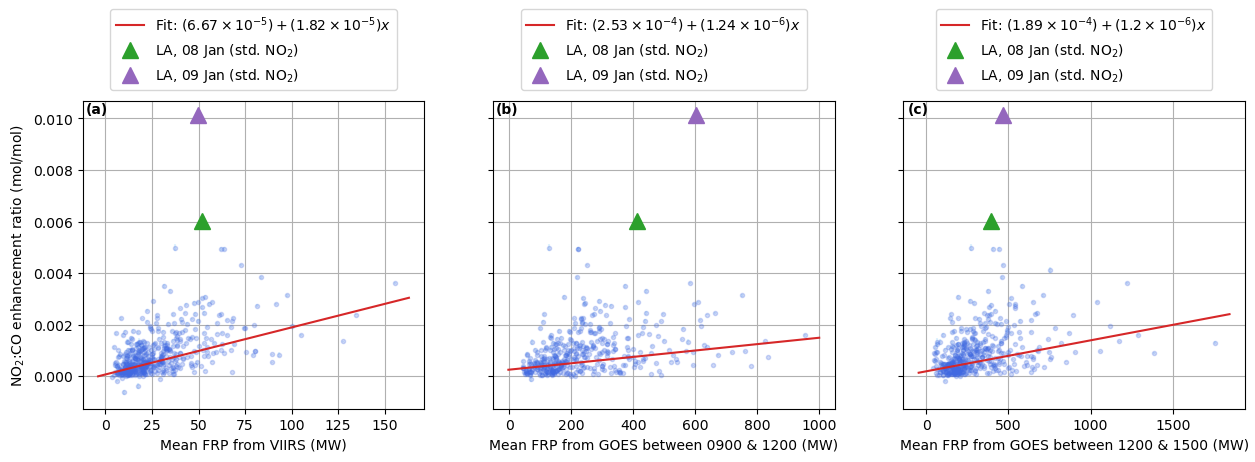

In [50]:
make_er_vs_frp_plot(include_custom=False)
plt.savefig('figures/er-vs-frp-std-only.pdf', bbox_inches='tight')

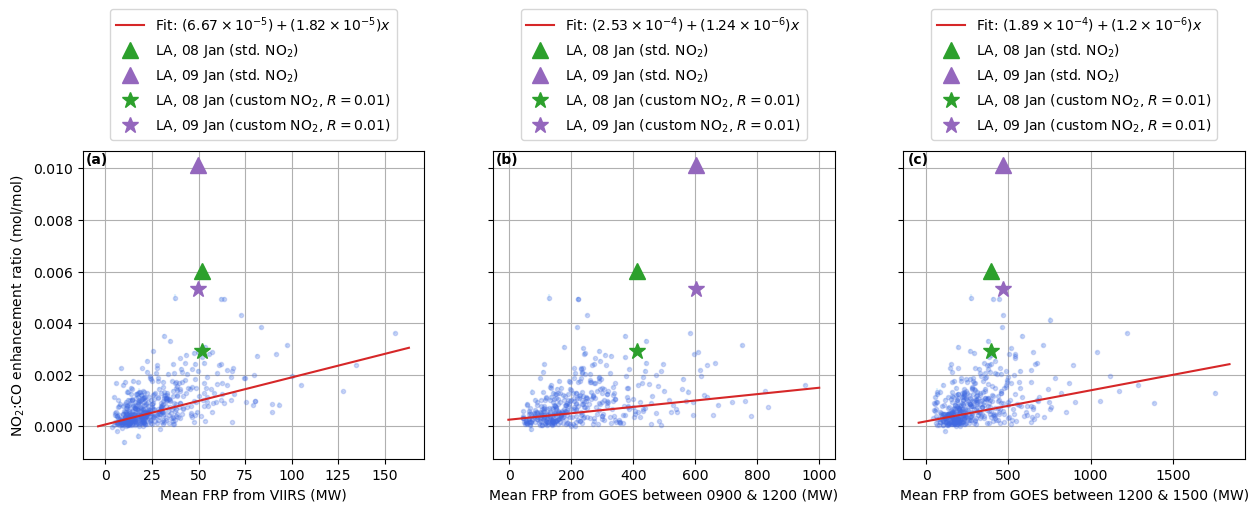

In [41]:
make_er_vs_frp_plot(include_custom=True)
plt.savefig('figures/er-vs-frp.pdf', bbox_inches='tight')

In [27]:
def make_custom_no2_comparison_plot(
    local_hour_limits=((9,12), (12,15)), frp_provider=GOES_WEST_COAST_FRP, frp_delta=50.0,
    la_scenes=LA_CFG['scene'], west_coast_scenes=ANDERSON_CFG['scene'],
    la_dates=[pd.Timestamp(2025,1,8), pd.Timestamp(2025,1,9)],
    custom_enh_tropess_dirs=CUSTOM_ENH_DIRS_TROPESS, custom_enh_gaussian_dirs=CUSTOM_ENH_DIRS_GAUSSIAN,
    ax_height=4
):
    nx = len(la_dates)
    ny = len(local_hour_limits)
    _, axs = plt.subplots(ny, nx, figsize=(6*nx, ax_height*ny), gridspec_kw={'hspace': 0.35}, sharex=True)
    axs = axs.reshape(ny, nx)

    for ihr, hour_limits in enumerate(local_hour_limits):
        # First get the standard and custom data for the LA fires
        la_fires_all, west_coast_fires_all = load_retrievals_frp_er(
            frp_provider=frp_provider, la_scenes=la_scenes, west_coast_scenes=west_coast_scenes,
            hour_limits=hour_limits, include_custom=True,
            custom_enh_tropess_dirs=custom_enh_tropess_dirs, custom_enh_gaussian_dirs=custom_enh_gaussian_dirs,
        )
    
        # Now for each date, get the FRP of the LA fire and select the west coast fires
        # on either side for the plot.
        order = _scenario_order(la_fires_all)
        for iax, date in enumerate(la_dates):
            la_df, wc_df, frp_min, frp_max = limit_to_frp_range(la_fires_all=la_fires_all, west_coast_fires_all=west_coast_fires_all, date=date, frp_delta=frp_delta)
    
            ax = axs[ihr, iax]
            wc_handles = sns.stripplot(wc_df, x='er', y='scenario_label', order=order, color='gray', size=4, ax=ax)
            la_handles = sns.stripplot(la_df, x='er', y='scenario_label', order=order, color='red', marker='*', size=12, ax=ax)
            h1, h2 = hour_limits
            ax.set_title(f'LA fires for {date:%Y-%m-%d}\n2020/21 fires with FRP $\\in$ [{frp_min:.0f}, {frp_max:.0f}] MW\nbetween {h1}:00 and {h2}:00 local')
            ax.grid(True)
            ax.set_xlabel('NO$_2$:CO enhancement ratio (mol/mol)')
            ax.set_ylabel('')
            if iax > 0:
                ylabels = ax.get_yticklabels()
                ax.set_yticklabels([])
            # ax.get_legend().remove()
    
        ax.legend(
            loc='center left',
            bbox_to_anchor=(1.025, 0.5),
            handles=[
                mlines.Line2D([0], [0], marker='*', color='red', markersize=12, ls='none', label='LA fires'),
                mlines.Line2D([0], [0], marker='o', color='gray', markersize=4, ls='none', label='2020/21 fires'),
            ]
        )

        return axs


def load_retrievals_frp_er(
    frp_provider, la_scenes, west_coast_scenes, hour_limits, include_custom: bool = True,
    custom_enh_tropess_dirs=CUSTOM_ENH_DIRS_TROPESS, custom_enh_gaussian_dirs=CUSTOM_ENH_DIRS_GAUSSIAN,
):
    print('Loading LA fire data')
    la_fires_std = collect_all_custom_retrievals(
        frp_provider, frp_range=(0, np.inf),
        scenes=la_scenes, local_hour_limits=hour_limits,
        custom_enh_dirs=[Path('static-data/tropomi/enhancements/')]
    )

    if include_custom:
        la_fires_cust = collect_all_custom_retrievals(
            frp_provider, frp_range=(0, np.inf),
            scenes=la_scenes, local_hour_limits=hour_limits,
            custom_enh_dirs=custom_enh_tropess_dirs + custom_enh_gaussian_dirs
        )
        la_fires_all = pd.concat([la_fires_std, la_fires_cust])
    else:
        la_fires_all = la_fires_std

    # Then do the same for the 2020/21 fires. We'll handle filtering on FRP ourselves
    print('Loading west coast standard data')
    west_coast_fires_std = collect_all_custom_retrievals(
        frp_provider, frp_range=(0, np.inf),
        scenes=west_coast_scenes, local_hour_limits=hour_limits,
        custom_enh_dirs=[Path('static-data/tropomi/enhancements/')]
    )

    if include_custom:
        print('Loading west coast custom data')
        west_coast_fires_cust = collect_all_custom_retrievals(
            frp_provider, frp_range=(0, np.inf),
            scenes=west_coast_scenes, local_hour_limits=hour_limits,
            custom_enh_dirs=custom_enh_gaussian_dirs
        )
        west_coast_fires_all = pd.concat([west_coast_fires_std, west_coast_fires_cust])
    else:
        west_coast_fires_all = west_coast_fires_std

    return la_fires_all, west_coast_fires_all

def collect_all_custom_retrievals(frp_provider, frp_range, scenes, local_hour_limits, custom_enh_dirs, frp_col='mean_frp'):
    dfs = []
    for enh_dir in custom_enh_dirs:
        er_provider = nberf.SlopeErMultiSceneProvider(scenes, enh_dir)
        matched_df = nberf.match_frps_to_ers_many_files(
            frp=frp_provider, er=er_provider, scenes=scenes, local_hour_limits=local_hour_limits
        )
        matched_df = matched_df[[frp_col, 'er', 'er_unc', 'scene', 'subscene', 'fire_start']].rename(columns={frp_col: 'frp'})

        ff = (matched_df.frp >= frp_range[0]) & (matched_df.frp <= frp_range[1])
        matched_df = matched_df[ff]
        
        sid, slabel = _enh_dir_to_scenario(enh_dir)
        matched_df['scenario_id'] = sid
        matched_df['scenario_label'] = slabel
        dfs.append(matched_df)
    return pd.concat(dfs)


def limit_to_frp_range(la_fires_all, west_coast_fires_all, date, frp_delta: float = 50):
    la_df = la_fires_all.loc[date]
    if len(la_df.shape) == 1:
        # got a series, convert back to a one-row dataframe
        la_df = pd.DataFrame(la_df).T
    ii = la_df.scenario_id == 'standard'
    la_frp = la_df.loc[ii, 'frp'].item()
    frp_min = la_frp - frp_delta
    frp_max = la_frp + frp_delta
    ff = (west_coast_fires_all.frp >= (la_frp - frp_delta)) & (west_coast_fires_all.frp <= (la_frp + frp_delta))
    wc_df = west_coast_fires_all.loc[ff, :]
    return la_df, wc_df, frp_min, frp_max

def _enh_dir_to_scenario(d: Path):
    if 'gaussian' in d.parts:
        i = d.parts.index('gaussian')
        m = re.match(r'(\d+)hPa-by-(\d+)hPa-(\d+)ppb', d.parts[i+1])
        pmid = m.group(1)
        pwidth = m.group(2)
        max_no2 = m.group(3)
        # For now, all have the same width, so skip that to make the labels shorter
        assert pwidth == '50', f'Must have added a new width, expected 50, got {pwidth}'
        sid = f'gaussian-{pmid}mid-{pwidth}width-{max_no2}max'
        label = f'Gaussian with max {max_no2} ppb NO$_2$ at {pmid} hPa'
    elif 'gaussian-aerosol' in d.parts:
        i = d.parts.index('gaussian-aerosol')
        m = re.match(r'(\d+)hPa-by-(\d+)hPa-(\d+)ppb-([0-9.]+)sw', d.parts[i+1])
        pmid = m.group(1)
        pwidth = m.group(2)
        max_no2 = m.group(3)
        sw = m.group(4)
        # For now, all have the same width, so skip that to make the labels shorter
        assert pwidth == '50', f'Must have added a new width, expected 50, got {pwidth}'
        sid = f'gaussian-{pmid}mid-{pwidth}width-{max_no2}max-{sw}sw'
        label = f'Gaussian with max {max_no2} ppb NO$_2$ at {pmid} hPa, SW = {sw} below'
    elif 'tropess-dco-ratio' in d.parts:
        i = d.parts.index('tropess-dco-ratio')
        m = re.match(r'ratio-(\d+\.\d+)', d.parts[i+1])
        ratio = float(m.group(1))
        sid = f'dco_ratio-{ratio:.2f}-no2_to_co'
        label = f'TROPESS CO-derived with NO$_2$:CO = {ratio:.2f}'
    elif 'wrf-chem' in d.parts:
        return 'wrfchem', 'WRF-Chem'
    elif 'tropomi-custom' not in d.parts:
        return 'standard', 'Standard'
    else:
        raise NotImplementedError(f'Scenario label for enhancement directory = {d}')

    return sid, label

def _scenario_order(df_with_scenarios):
    def _scenario_key(sid):
        if sid == 'standard':
            return (0,)
        elif sid.startswith('dco_ratio'):
            r = float(sid.split('-')[1])
            return (1, r)
        elif sid.startswith('wrf'):
            return (1, 1000)
        elif sid.startswith('gaussian'):
            m = re.search(r'(\d+)mid-(\d+)width-(\d+)max', sid)
            pmid, pwidth, max_no2 = float(m.group(1)), float(m.group(2)), float(m.group(3))
            m2 = re.search(r'([0-9.]+)sw', sid)
            if m2 is None:
                sw = 0.0
            else:
                sw = float(m2.group(1))
            return (2, pmid, pwidth, max_no2, sw)
        else:
            raise NotImplementedError(f'Scenario ID = {sid}')
    scenarios = df_with_scenarios[['scenario_id', 'scenario_label']].set_index('scenario_id')['scenario_label']
    sids = scenarios.index.unique().to_list()
    sids.sort(key=_scenario_key)
    return [scenarios[k].iloc[0] for k in sids]

Loading LA fire data
Loading west coast standard data
Loading west coast custom data


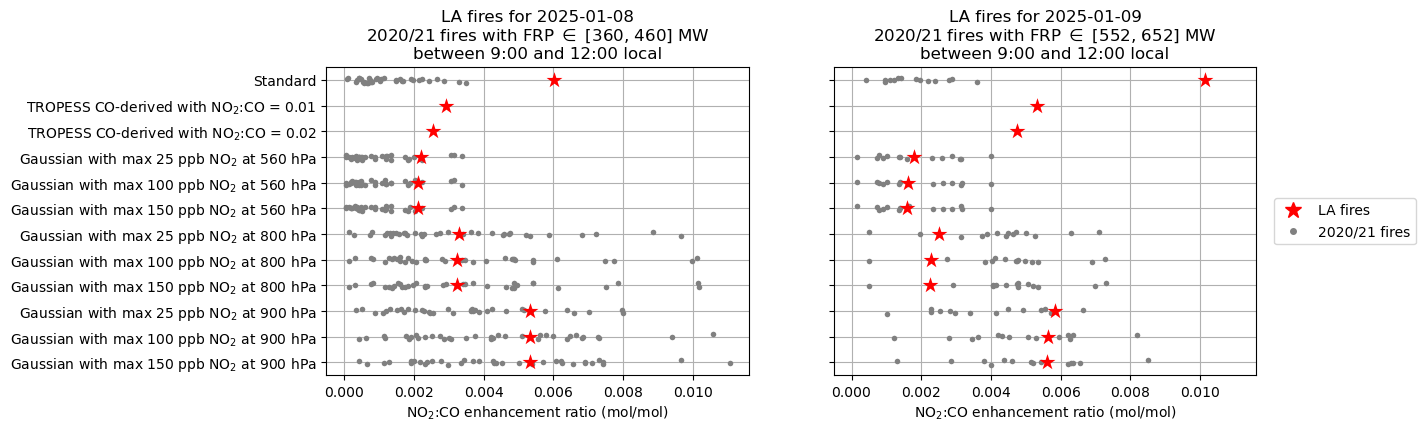

In [47]:
make_custom_no2_comparison_plot(local_hour_limits=[(9,12)])
plt.savefig('figures/custom-no2-scenarios-0900-1200.pdf', bbox_inches='tight')

Again, but with the aerosol and WRF-Chem tests included.

Loading LA fire data
Loading west coast standard data
Loading west coast custom data


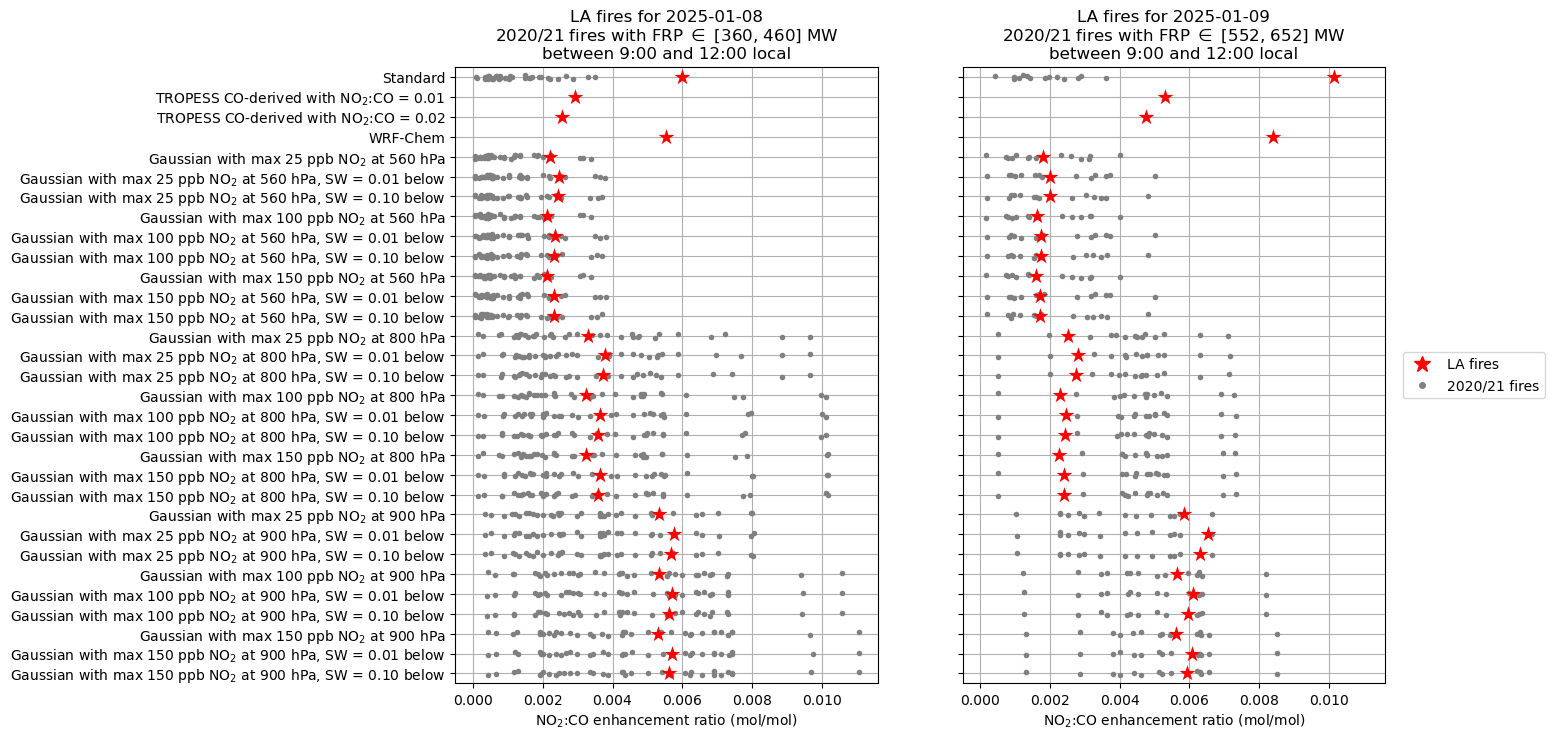

In [30]:
make_custom_no2_comparison_plot(local_hour_limits=[(9,12)], ax_height=8, custom_enh_tropess_dirs=ALL_LA_ONLY_CUSTOM_ENH_DIRS, custom_enh_gaussian_dirs=ALL_CUSTOM_GAUSSIAN_ENH_DIRS)
plt.savefig('figures/custom-no2-scenarios-with-aerosol-cases-0900-1200.pdf', bbox_inches='tight')

Loading LA fire data
Loading west coast standard data
Loading west coast custom data


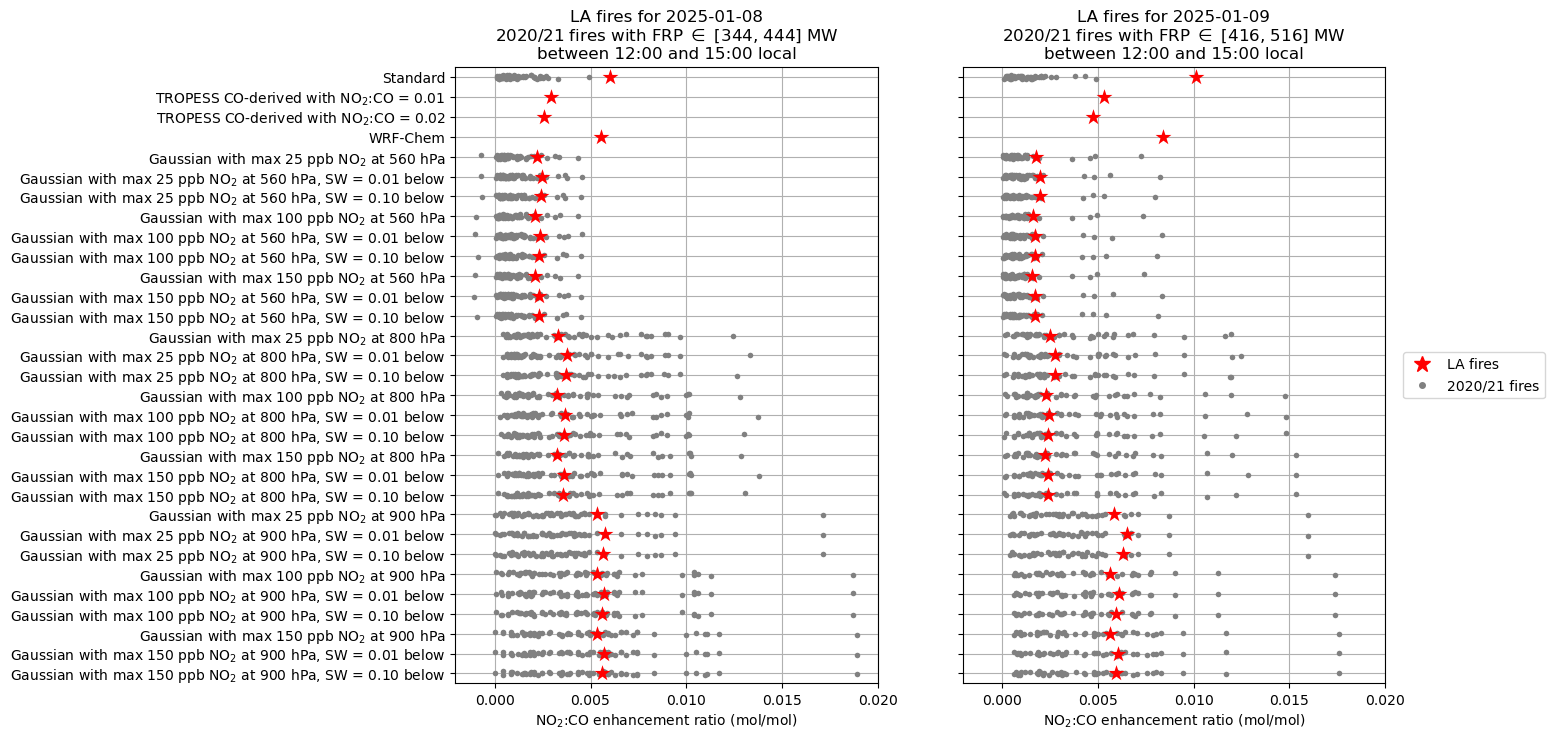

In [31]:
axs = make_custom_no2_comparison_plot(local_hour_limits=[(12,15)], ax_height=8, custom_enh_tropess_dirs=ALL_LA_ONLY_CUSTOM_ENH_DIRS, custom_enh_gaussian_dirs=ALL_CUSTOM_GAUSSIAN_ENH_DIRS)
for ax in axs.ravel():
    ax.set_xticks(np.arange(0, 0.021, 0.005))
plt.savefig('figures/custom-no2-scenarios-with-aerosol-cases-1200-1500.pdf', bbox_inches='tight')


The following figure is an example to explain why the aerosol test cases had such small effects.

In [53]:
def scattering_weight_jan9_example_plot(match_data):
    dno2 = 1e3 * (match_data['cust_aer_no2'] - match_data['cust_prior_no2'])
    no2_slant = 1e3 * match_data['cust_prior_no2'] * match_data['cust_prior_amf']

    i_dno2 = np.flatnonzero(dno2 > 0.06).item()
    i_slant = np.flatnonzero(no2_slant > 0.77).item()

    _, axs = plt.subplots(1, 2, figsize=(12,4), sharey=True)
    ax = axs[0]
    p = match_data['pres']*1e-2
    ax.plot(match_data['std_sw'][i_slant], p[i_slant], ls='-', marker='.', color='blue', label='Largest NO$_2$ SCD, std.')
    ax.plot(match_data['cust_aer_sw'][i_slant], p[i_slant], ls='--', marker='.', color='royalblue', label='Largest NO$_2$ SCD, cust.')
    ax.plot(match_data['std_sw'][i_dno2], p[i_dno2], ls='-', color='red', marker='.', label=r'Largest $\Delta$NO$_2$ VCD, std.')
    ax.plot(match_data['cust_aer_sw'][i_dno2], p[i_dno2], ls='--', marker='.', color='salmon', label=r'Largest $\Delta$NO$_2$ VCD, cust.')
    ax.invert_yaxis()
    ax.set_xlabel('Scattering weight (unitless)')
    ax.set_ylabel('Pressure (hPa)')
    ax.grid(True)

    ax = axs[1]
    ax.plot(match_data['std_sw'][i_slant] * match_data['cust_prior_shape'][i_slant], p[i_slant], ls='-', marker='.', color='blue', label='Largest NO$_2$ SCD, std.')
    ax.plot(match_data['cust_aer_sw'][i_slant] * match_data['cust_aer_shape'][i_slant], p[i_slant], ls='--', marker='.', color='royalblue', label='Largest NO$_2$ SCD, cust.')
    ax.plot(match_data['std_sw'][i_dno2] * match_data['cust_prior_shape'][i_dno2], p[i_dno2], ls='-', color='red', marker='.', label=r'Largest $\Delta$NO$_2$ VCD, std.')
    ax.plot(match_data['cust_aer_sw'][i_dno2] * match_data['cust_aer_shape'][i_dno2], p[i_dno2], ls='--', marker='.', color='salmon', label=r'Largest $\Delta$NO$_2$ VCD, std.')
    ax.legend(ncol=4, loc='lower right', bbox_to_anchor=(1, 1.025))
    ax.set_xlabel('Scattering weight times profile shape (unitless)')
    ax.grid(True)

    jplt.label_subplots(axs, xpos=0.06)

In [33]:
JAN9_SW_MATCH = nbtrcrc.match_custom_sw_to_orig(
    'static-data/tropomi-custom/gaussian-aerosol/560hPa-by-50hPa-25ppb-0.01sw/l2/no2/S5P_CUST_L2__NO2____20250109T000000_20250109T000000_XXXXX_YY_ZZZZZZ_20260731T173416.nc',
    nbcst.LA_EXTENT
)

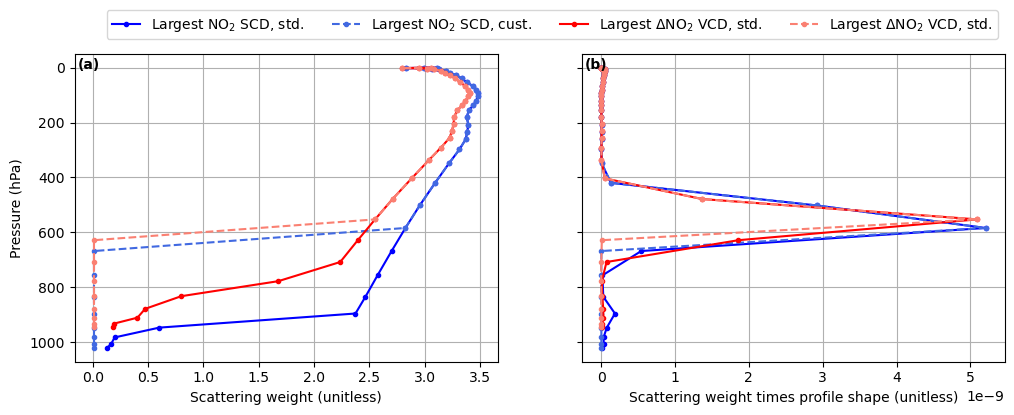

In [54]:
scattering_weight_jan9_example_plot(JAN9_SW_MATCH)
plt.savefig('figures/jan9-custom-aerosol-sw-example.pdf', bbox_inches='tight')

And this looks at the difference among the standard, TROPESS-derived, and WRF-Chem profiles:

In [12]:
def plot_prior_profile_comparison(date, extent, xlim=None):
    tropomi_data, _ = make_custom_l2.load_tropomi_l2_data(date, extent)
    time = tropomi_data['time']
    lon = tropomi_data['lon']
    lat = tropomi_data['lat']
    scd = tropomi_data['no2_trop'] * tropomi_data['amf_trop'] * 1e3 #* 6.022e23 / 1e4
    pres = np.nanmean(tropomi_data['pres_edges'], axis=2)
    colors = jplt.ColorMapper.from_data(scd, cmap='viridis')
    
    _, axs = plt.subplots(1, 4, figsize=(15,5), gridspec_kw={'width_ratios': [20, 20, 20, 1]})
    tropomi_prior = make_custom_l2.TropomiPriorLatLonPresInterp.for_date(date)
    tropess_hybrid = make_custom_l2.COEnhtoNO2LatLonPresInterp.for_date(0.01, date, pd.Timestamp(2025,1,1), pd.Timestamp(2025,1,6))
    wrfchem_prior = make_custom_l2.WrfLatLonPresInterp.from_file('static-data/wrf-chem/wrfout_d02_2025-01-07_20_pp')
    for (t, x, y, p, col) in zip(time, lon, lat, pres, scd):
        ax = axs[0]
        ax.plot(tropomi_prior(x, y, p, t)*1e9, p*.01, color=colors(col))

        ax = axs[1]
        ax.plot(tropess_hybrid(x, y, p, t)*1e9, p*.01, color=colors(col))

        ax = axs[2]
        ax.plot(wrfchem_prior(x, y, p, t)*1e9, p*.01, color=colors(col))

    axs[0].set_ylabel('Pressure (hPa)')
    axs[0].set_title('TROPOMI std.')
    axs[1].set_title('TROPESS NO$_2$:CO = 0.01 mol mol$^{-1}$')
    axs[2].set_title('WRF-Chem')
    for ax in axs[:3]:
        ax.set_xlabel('NO$_2$ (ppb)')
        ax.invert_yaxis()
        ax.grid(True)
        if xlim is not None:
            ax.set_xlim(xlim)

    plt.colorbar(colors, cax=axs[3], label='NO$_2$ slant column density (mmol m$^{-2}$)')

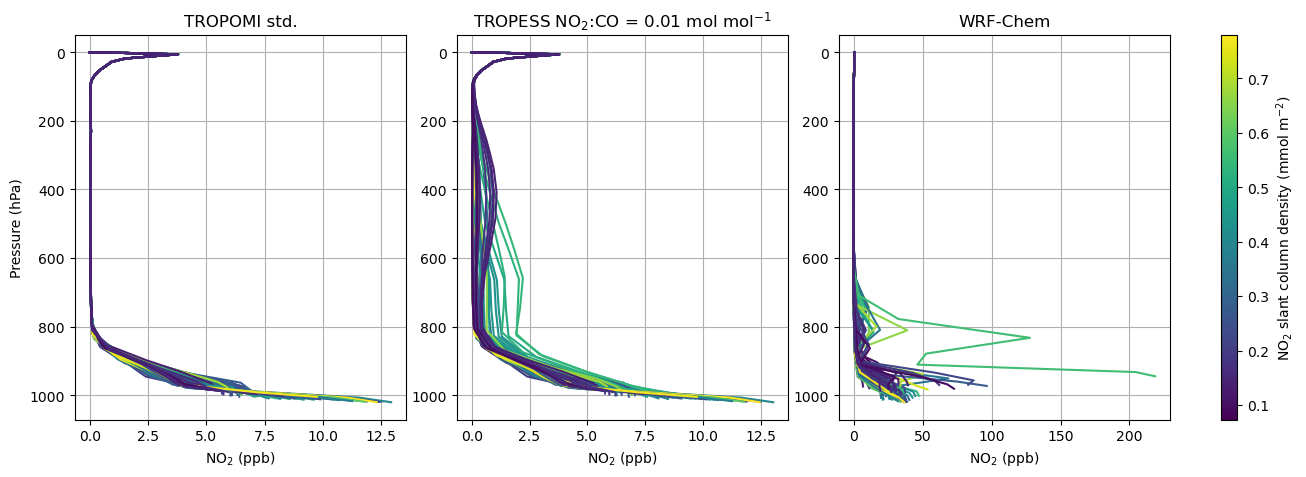

In [13]:
plot_prior_profile_comparison(pd.Timestamp(2025,1,9), extent=[-118.7, -117.7, 33.9, 34.2])
plt.savefig('figures/custom-prior-3way-comparison.pdf', bbox_inches='tight')

## FRP difference

To quote the FRP difference on Jan 9th between peak and afternoon, let's get the exact values from the violin plots.

In [51]:
def compare_la_fire_peak(date, tropomi_hr=13.5):
    _, la_fires_mean = _prep_frp_er_dfs(False)
    la_fires_by_hour = nbplt.make_goes_frp_by_hour_df(GOES_WEST_COAST_FRP, LA_CFG['scene'])
    hours = np.full(len(la_fires_by_hour), np.nan)
    frps = np.full(len(la_fires_by_hour), np.nan)
    i = -1
    for hr_range, hr_df in la_fires_by_hour:
        i += 1
        hours[i] = np.mean(hr_range)
        try:
            frps[i] = hr_df.loc[date, 'mean_frp']
        except KeyError:
            # date not available for this hour range, so leave the NaN
            pass
    df = pd.DataFrame({'mean_frp': frps}, index=hours)
    max_frp = df.mean_frp.max()
    hr_max = df.mean_frp.idxmax()
    trop_frp = df.loc[tropomi_hr, 'mean_frp']
    afternoon_mean = la_fires_mean['GOES']['1200-1500']['std. NO$_2$'].loc[date, 'mean_frp']
    print(f'Peak FRP at {hr_max} = {max_frp:.0f} MW, vs. at {tropomi_hr} = {trop_frp:.0f} MW.', end=' ')
    print(f'Difference = {max_frp - trop_frp:.0f} MW.')
    print(f'Afternoon mean FRP = {afternoon_mean:.0f} MW, difference vs. max = {max_frp - afternoon_mean:.0f} MW')

In [52]:
compare_la_fire_peak('2025-01-09')

Peak FRP at 11.5 = 769 MW, vs. at 13.5 = 421 MW. Difference = 348 MW.
Afternoon mean FRP = 466 MW, difference vs. max = 303 MW


## Aerosol properties

This will look at the aerosol properties as observed by TROPOMI in the comparison plumes.

In [54]:
def plot_mean_plume_aerosol_properties(hour_limits, la_date, legend_on='SSA', cmap='GnBu', manual_excludes=None, highlight_scene=None, frp_delta=50.0, vmin=0.0, vmax=1.0, axs=None):
    la_fires, west_coast_fires = load_retrievals_frp_er(
        frp_provider=GOES_WEST_COAST_FRP, la_scenes=LA_CFG['scene'], west_coast_scenes=ANDERSON_CFG['scene'],
        hour_limits=hour_limits, include_custom=False
    )
    la_df, wc_df, _, _ = limit_to_frp_range(la_fires_all=la_fires, west_coast_fires_all=west_coast_fires, date=la_date, frp_delta=frp_delta)
    la_frp = la_df['frp'].item()

    ii_exclude = np.zeros(wc_df.shape[0], dtype=bool)
    if manual_excludes is not None:
        for ex in manual_excludes:
            xx = (wc_df.index == pd.to_datetime(ex['date'])) & (wc_df.scene == ex['scene']) & (wc_df.subscene == ex.get('subscene', 'main'))
            ii_exclude[xx] = True
            if xx.sum() == 0:
                print(f'Warning: no match for manual exclude {ex}')
    

    la_er_aer_df = _load_many_plume_aerosol_with_er(la_df)
    wc_er_aer_df = _load_many_plume_aerosol_with_er(wc_df)

    if highlight_scene is None:
        ii_highlight = np.zeros(wc_er_aer_df.shape[0], dtype=bool)
    else:
        ii_highlight = wc_er_aer_df.scene == highlight_scene['scene']

    variables = la_er_aer_df.columns.get_level_values(0).unique()
    nx = variables.size - 3
    if axs is None:
        _, axs = plt.subplots(1, nx, figsize=(4*nx, 4), gridspec_kw={'wspace': 0.4})
    elif len(axs) != nx:
        raise ValueError(f'need {nx} axes, got {len(axs)}')

    iax = -1
    units_dict = {'AOD': 'unitless', 'SSA': 'unitless', 'ALH': 'm'}
    

    for var in variables:
        if var in {'ER', 'scene', 'subscene'}:
            continue

        iax += 1
        ax = axs[iax] 
        if vmin is None:
            vmin = min(la_er_aer_df[var].fraction_good.min(), wc_er_aer_df[var].fraction_good.min())
        if vmax is None:
            vmax = max(la_er_aer_df[var].fraction_good.max(), wc_er_aer_df[var].fraction_good.max())
        ax.scatter(la_er_aer_df['ER'], la_er_aer_df[var]['mean'], c=la_er_aer_df[var]['fraction_good'], s=120, vmin=vmin, vmax=vmax, cmap=cmap, marker='*')
        ax.scatter(
            wc_er_aer_df.loc[ii_exclude, 'ER'], wc_er_aer_df[var].loc[ii_exclude, 'mean'],
            c=wc_er_aer_df[var].loc[ii_exclude, 'fraction_good'],
            vmin=vmin, vmax=vmax, cmap=cmap, marker='X'
        )
        if highlight_scene is not None:
            ax.scatter(
                wc_er_aer_df.loc[~ii_exclude & ii_highlight, 'ER'], wc_er_aer_df[var].loc[~ii_exclude & ii_highlight, 'mean'],
                c=wc_er_aer_df[var].loc[~ii_exclude & ii_highlight, 'fraction_good'],
                vmin=vmin, vmax=vmax, cmap=cmap, marker=highlight_scene.get('marker', '^')
            )
        h = ax.scatter(
            wc_er_aer_df.loc[~ii_exclude & ~ii_highlight, 'ER'], wc_er_aer_df[var].loc[~ii_exclude & ~ii_highlight, 'mean'],
            c=wc_er_aer_df[var].loc[~ii_exclude & ~ii_highlight, 'fraction_good'],
            vmin=vmin, vmax=vmax, cmap=cmap
        )
        plt.colorbar(h, ax=ax, label='Fraction good grid cells')
        ax.grid(True)
        ax.set_xlabel('NO$_2$:CO ER (mol/mol)')
        ax.set_ylabel(f'{var} ({units_dict[var]})')
        if var == legend_on:
            ncol = 2
            handles = [
                mlines.Line2D([0], [0], color='k', marker='*', ls='none', markersize=12, label=f'LA fires on {la_date:%d %b}'),
                mlines.Line2D([0], [0], color='k', marker='o', ls='none', label=f'2020/21 fires $\\in[{la_frp - frp_delta:.0f}, {la_frp + frp_delta:.0f}]$ MW'),
            ]
            if highlight_scene is not None:
                handles.insert(
                    1,
                    mlines.Line2D(
                        [0], [0], color='k', marker=highlight_scene.get('marker', '^'), ls='none',
                        label=highlight_scene['label']
                    )
                )
                ncol += 1
            if np.any(ii_exclude):
                handles.append(mlines.Line2D([0], [0], color='k', marker='X', ls='none', label=f'2020/21 fires (manually excluded)'))
                ncol += 1
            
            ax.legend(handles=handles, ncol=ncol, loc='lower center', bbox_to_anchor=(0.5, 1.025))

    # Collect just the variables we plotted
    la_er_aer_df['cluster_index'] = 0
    wc_er_aer_df['cluster_index'] = 1
    return pd.concat([la_er_aer_df, wc_er_aer_df.loc[~ii_exclude]]).reset_index(drop=True)
    


def _load_many_plume_aerosol_with_er(df_in):
    out_rows = []
    for date, row in df_in.iterrows():
        tmp_row = _load_plume_aerosol(row['scene'], row['subscene'], date)
        new_row = {('ER', ''): row['er'], ('scene', ''): row['scene'], ('subscene', ''): row['subscene']}
        for grp, values in tmp_row.items():
            new_row.update({(grp, k): v for k, v in values.items()}) 
        out_rows.append(new_row)
    df_out = pd.DataFrame(out_rows)
    df_out.columns = pd.MultiIndex.from_tuples(df_out.columns)
    return df_out

def _load_plume_aerosol(scene_name, subscene_name, date):
    plume_file = f'static-data/tropomi/plume/plumeinfo_{scene_name}_{subscene_name}_{date:%Y%m%d}.nc'
    with Dataset(plume_file) as ds:
        out = dict()
        for grpname, grp in ds.groups.items():
            out[grpname] = {'mean': grp['mean'][tuple()].item(), 'fraction_good': grp['fraction_good'][tuple()].item()}
    return out

In [60]:
AEROSOL_DATA_DICT = dict()

Loading LA fire data
Loading west coast standard data


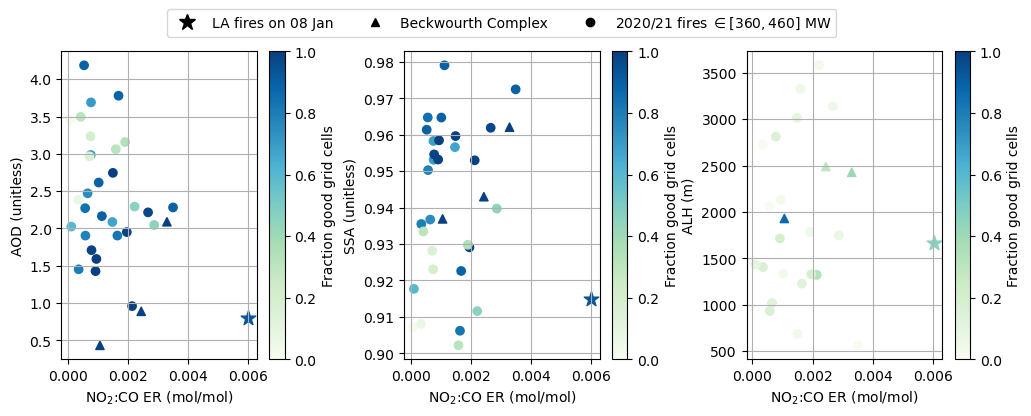

In [61]:
AEROSOL_DATA_DICT['jan08'] = plot_mean_plume_aerosol_properties(
    (9,12), pd.Timestamp(2025,1,8),
    highlight_scene={'scene': 'anderson_beckwourth', 'label': 'Beckwourth Complex'}
)
plt.savefig('figures/aerosol_comparison_to_jan08.pdf', bbox_inches='tight')

Loading LA fire data
Loading west coast standard data


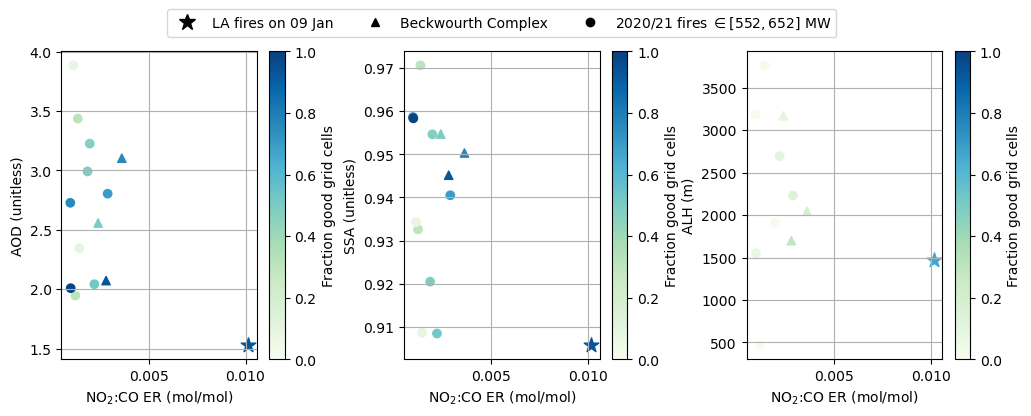

In [62]:
AEROSOL_DATA_DICT['jan09'] = plot_mean_plume_aerosol_properties(
    (9,12), pd.Timestamp(2025,1,9),
    highlight_scene={'scene': 'anderson_beckwourth', 'label': 'Beckwourth Complex'}
)
plt.savefig('figures/aerosol_comparison_to_jan09.pdf', bbox_inches='tight')

In [63]:
def replace_la_er_with_custom(aer_data, date, scenario_id):
    aer_data = aer_data.copy()
    la_df, _ = load_retrievals_frp_er(
        frp_provider=GOES_WEST_COAST_FRP, la_scenes=LA_CFG['scene'], west_coast_scenes=ANDERSON_CFG['scene'][:1],
        hour_limits=(9,12), include_custom=True,
    )
    la_df = la_df[la_df.scenario_id == scenario_id]
    i_la = aer_data.index[aer_data.cluster_index == 0].item()
    aer_data.loc[i_la, 'ER'] = la_df.loc[date, 'er']
    return aer_data

In [64]:
CUSTOM_AEROSOL_DATA_DICT = dict()
for date in pd.date_range('2025-01-08', '2025-01-09'):
    dkey = date.strftime('%b%d').lower()
    ddict = CUSTOM_AEROSOL_DATA_DICT.setdefault(dkey, dict())
    for sid in ['dco_ratio-0.01-no2_to_co', 'dco_ratio-0.02-no2_to_co']:
        ddict[sid] = replace_la_er_with_custom(
            AEROSOL_DATA_DICT[dkey], date, sid
        )

Loading LA fire data
Loading west coast standard data
Loading west coast custom data
Loading LA fire data
Loading west coast standard data
Loading west coast custom data
Loading LA fire data
Loading west coast standard data
Loading west coast custom data
Loading LA fire data
Loading west coast standard data
Loading west coast custom data


In [65]:
'jan08'.capitalize()

'Jan08'

In [112]:
def simplify_aerosol_df(df, dkey):
    day = dkey.capitalize().replace('0', ' ')
    out = pd.DataFrame({
        "day": day,
        "ER": df[("ER", "")],
        "scene": df[("scene", "")],
        "subscene": df[("subscene", "")],
        "AOD": df[("AOD", "mean")],
        "AOD_good": df[("AOD", "fraction_good")],
        "SSA": df[("SSA", "mean")],
        "SSA_good": df[("SSA", "fraction_good")],
        "ALH": df[("ALH", "mean")],
        "ALH_good": df[("ALH", "fraction_good")],
        "is_LA": df[("cluster_index", "")].eq(0),
    })
    return out.reset_index(drop=True)

def aerosol_distance(df, dkey, props, recenter=True):
    df = simplify_aerosol_df(df, dkey)
    use = df[props + ["is_LA"]].dropna().copy()
    comp = use[~use.is_LA]
    la = use[use.is_LA]

    scaler = RobustScaler().fit(comp[props])
    if recenter:
        center = np.median(scaler.transform(comp[props]), axis=0)
    else:
        center = 0

    comp_d = np.linalg.norm(scaler.transform(comp[props]) - center, axis=1)
    la_d = np.linalg.norm(scaler.transform(la[props]) - center, axis=1)[0]
    pct = percentileofscore(comp_d, la_d, kind="mean")
    return la_d, pct, len(comp)


def make_aerosol_correlation_df(aerosol_data_dict, properties=['AOD', 'SSA', 'ALH'], exclude_la=False):
    corr_rows = []
    for dkey, df in aerosol_data_dict.items():
        for prop in properties:
            if exclude_la:
                ii = df['cluster_index'] != 0
            else:
                ii = np.ones(df.shape[0], dtype=bool)
            use = df.loc[ii, [(prop, 'mean'), ('ER', '')]].dropna()
            use.columns = [c[0] for c in use.columns]
            rho, p = spearmanr(use[prop], use.ER)
            corr_rows.append([dkey, prop, len(use), rho, p])
    
    corr = pd.DataFrame(corr_rows, columns=["day", "property", "N", "Spearman rho", "p value"])
    return corr

In [95]:
for dkey, df in AEROSOL_DATA_DICT.items():
    d2, p2, n2 = aerosol_distance(df, dkey, ["AOD", "SSA"])
    d3, p3, n3 = aerosol_distance(df, dkey, ["AOD", "SSA", "ALH"])
    print(f"{dkey}: AOD+SSA distance percentile = {p2:.1f}% (N={n2})")
    print(f"        AOD+SSA+ALH distance percentile = {p3:.1f}% (N={n3})")

jan08: AOD+SSA distance percentile = 93.9% (N=33)
        AOD+SSA+ALH distance percentile = 91.7% (N=24)
jan09: AOD+SSA distance percentile = 100.0% (N=13)
        AOD+SSA+ALH distance percentile = 100.0% (N=10)


In [100]:
make_aerosol_correlation_df(AEROSOL_DATA_DICT).round(3)

,day,property,N,Spearman rho,p value
0,jan08,AOD,34,-0.299,0.086
1,jan08,SSA,34,0.141,0.425
2,jan08,ALH,25,0.065,0.756
3,jan09,AOD,14,-0.134,0.648
4,jan09,SSA,14,-0.376,0.185
5,jan09,ALH,11,-0.182,0.593


In [114]:
make_aerosol_correlation_df(AEROSOL_DATA_DICT, exclude_la=True).round(3)

,day,property,N,Spearman rho,p value
0,jan08,AOD,33,-0.239,0.181
1,jan08,SSA,33,0.217,0.225
2,jan08,ALH,24,0.084,0.695
3,jan09,AOD,13,0.082,0.789
4,jan09,SSA,13,-0.220,0.471
5,jan09,ALH,10,-0.006,0.987


In [108]:
def make_er_prediction_df(std_df_dict, cust_df_dict, ax=None):
    rows = []
    keys = []
    for dkey, std_df in std_df_dict.items():
        if dkey == 'README':
            continue
        cust_df_date = cust_df_dict[dkey]

        y_obs, y_pred, y_ci_lower, y_ci_upper = _predict_ols_model(std_df)
        this_row = {
            ('pred', 'value'): y_pred,
            ('pred', 'ci_lower'): y_ci_lower,
            ('pred', 'ci_upper'): y_ci_upper,
            ('obs', 'std'): y_obs
        }
        for key, cust_df in cust_df_date.items():
            y_obs_custom, y_pred_custom, _, _, = _predict_ols_model(cust_df)
            assert np.isclose(y_pred_custom, y_pred)
            this_row[('obs', key)] = y_obs_custom

        rows.append(this_row)
        keys.append(f'2025{dkey}')

    dates = pd.to_datetime(keys, format='%Y%b%d')
    df = pd.DataFrame(rows, index=dates)
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    return df


def plot_er_prediction(prediction_df, ax=None):
    ax = ax or plt.gca()
    n = 1 + prediction_df['obs'].shape[1]
    w = 0.45 / (n - 1)
    offsets = np.linspace(-0.25, 0.25, num=n)
    x = np.arange(prediction_df.shape[0])
    print(w, offsets)

    yerr = np.array([
        prediction_df['pred']['value'].to_numpy() - prediction_df['pred']['ci_lower'].to_numpy(),
        prediction_df['pred']['ci_upper'].to_numpy() - prediction_df['pred']['value'].to_numpy()
    ]).T
    ax.bar(x + offsets[0], prediction_df['pred']['value'], width=w, color='gray', label='Predicted')
    # It's annoyingly easier to just plot the CI values
    for xi, yli, yui in zip(x + offsets[0], prediction_df['pred']['ci_lower'], prediction_df['pred']['ci_upper']):
        ax.plot([xi, xi], [yli, yui], color='black')
    for i, (key, series) in enumerate(prediction_df['obs'].items(), start=1):
        if key == 'std':
            label = 'Observed LA - std. NO$_2$'
        else:
            m = re.match(r'dco_ratio-0.(\d+)', key)
            label = f'Obs. LA - cust. NO$_2$ ($\\Delta$NO$_2$:$\\Delta$CO = 0.{m.group(1)})'
        ax.bar(x + offsets[i], series, width=w, label=label)

    
    ax.set_xticks(x)
    ax.set_xticklabels(prediction_df.index.strftime('%b %d'))
    ax.set_ylabel('NO$_2$:CO ER (mol mol$^{-1}$)')
    ax.legend()
    ax.grid(True)
        


def _prep_ols_inputs(df, for_la, props):
    if for_la:
        ii = df.cluster_index == 0
    else:
        ii = df.cluster_index != 0
    df = df.loc[ii, [(k, 'mean') for k in props] + [('ER', '')]].dropna()
    df.columns = [c[0] for c in df.columns]
    X = sm.add_constant(df[props], has_constant='add')
    y = df['ER']
    return np.log10(y), X

def _predict_ols_model(df, props=['AOD', 'SSA']):
    y, X = _prep_ols_inputs(df, for_la=False, props=props)
    model = sm.OLS(y, X)
    fit = model.fit()
    y_la, X_la = _prep_ols_inputs(df, for_la=True, props=props)
    y_pred = 10 ** fit.predict(X_la).item()
    pred = fit.get_prediction(X_la).summary_frame(alpha=0.05)
    y_la = 10 ** y_la
    y_pred = 10 ** pred['mean'].item()
    y_ci_lower = 10 ** pred['obs_ci_lower'].item()
    y_ci_upper = 10 ** pred['obs_ci_upper'].item()
    return y_la.item(), y_pred, y_ci_lower, y_ci_upper

0.15 [-0.25       -0.08333333  0.08333333  0.25      ]


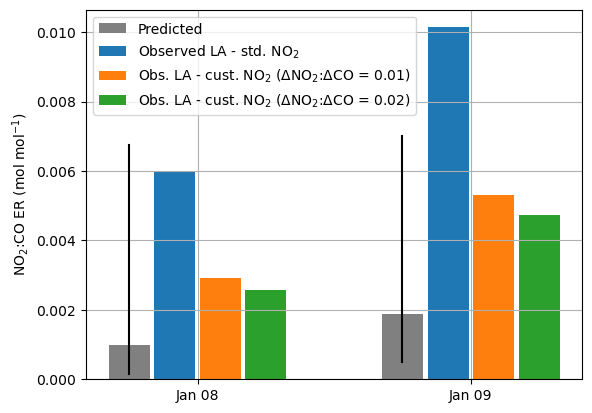

In [109]:
plot_er_prediction(
    make_er_prediction_df(AEROSOL_DATA_DICT, CUSTOM_AEROSOL_DATA_DICT)
)
plt.savefig('figures/predicted-er-from-aerosols.pdf', bbox_inches='tight')

In [7]:
def calfire_boxplot_comparison(calfire: pd.DataFrame, start_year=2000, ax=None):
    acre_per_km2 = 1 / 0.004046856
    yy = calfire.Year >= start_year

    # pull out the fires we want to highlight
    xx = (calfire['Year'].fillna(0).astype(int) == 2025) & (calfire['Fire Name'].isin(('PALISADES', 'EATON')))
    la_fires = calfire.loc[xx, :]
    other_fires = calfire.loc[~xx & yy, :]
    
    years = []
    areas = []
    for year, year_df in other_fires.groupby('Year'):
        year = int(year)
        years.append(year)
        areas.append(year_df['GIS Calculated Acres'].to_numpy() / acre_per_km2)

    if ax is None:
        _, ax = plt.subplots(figsize=(12,4))
    ax.boxplot(areas, positions=years)

    all_areas = np.concatenate(areas)
    for _, row in la_fires.iterrows():
        this_area = row['GIS Calculated Acres'] / acre_per_km2
        pctile = percentileofscore(all_areas, this_area)
        name = row['Fire Name'].lower().capitalize()
        ax.plot(
            row['Year'], this_area, ls='none', marker='^', markersize=12,
            label=f'{name} ({pctile:.0f}th %ile)'
        )
    
    ax.set_yscale('log')
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=90)
    ax.grid(True)
    ax.set_xlabel('Year')
    ax.set_ylabel('Burned area (km$^2$)')
    ax.legend(ncols=la_fires.shape[0], loc='lower center', bbox_to_anchor=(0.5, 1.025))

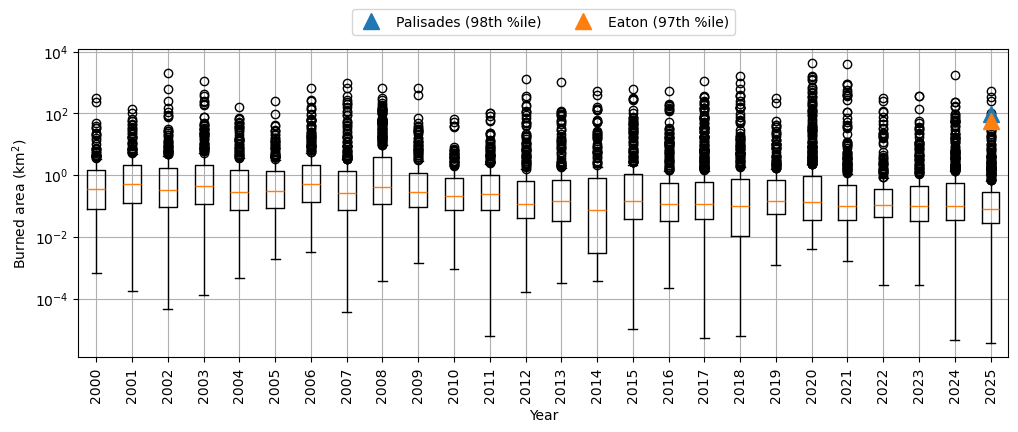

In [8]:
calfire_boxplot_comparison(CALFIRE_DF)
plt.savefig('figures/calfire-historical-comparison.pdf', bbox_inches='tight')